<a href="https://colab.research.google.com/github/vaibhavchoudhary44/Electricity-Fraud-Detection/blob/main/electricity_fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# %load /content/MASC ETD Colab.ipynb
{
 "cells": [
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "# MASC-ETD \u2014 Electricity Theft Detection\n",
    "**Missingness-Aware, Signature-based, Cost-aware detection on smart meter data**\n",
    "\n",
    "Run the cells top to bottom. Runtime > Run all works too.\n",
    "\n",
    "No GPU needed. Runtime type can stay on CPU.\n"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 1. Install dependencies"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "!pip -q install pandas numpy scipy scikit-learn matplotlib seaborn xgboost lightgbm imbalanced-learn shap\n",
    "print(\"done\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 2. Create the project files\n",
    "Each cell below writes one module to disk."
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "import os\n",
    "os.makedirs('src', exist_ok=True)\n",
    "open('src/__init__.py','w').close()\n",
    "print('src/ ready')"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "%%writefile src/config.py\n",
    "\"\"\"\n",
    "config.py\n",
    "Central configuration for the MASC-ETD pipeline.\n",
    "Change values here instead of editing the pipeline modules.\n",
    "\"\"\"\n",
    "\n",
    "from pathlib import Path\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Paths\n",
    "# ----------------------------------------------------------------------\n",
    "ROOT = Path(__file__).resolve().parent.parent\n",
    "DATA_DIR = ROOT / \"data\"\n",
    "OUTPUT_DIR = ROOT / \"outputs\"\n",
    "FIG_DIR = OUTPUT_DIR / \"figures\"\n",
    "\n",
    "DATA_DIR.mkdir(exist_ok=True)\n",
    "OUTPUT_DIR.mkdir(exist_ok=True)\n",
    "FIG_DIR.mkdir(exist_ok=True)\n",
    "\n",
    "# Path to the SGCC csv (data.csv after extracting data.zip/.z01/.z02)\n",
    "RAW_CSV = DATA_DIR / \"data.csv\"\n",
    "\n",
    "# Column names in the SGCC file\n",
    "ID_COL = \"CONS_NO\"\n",
    "LABEL_COL = \"FLAG\"\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Preprocessing\n",
    "# ----------------------------------------------------------------------\n",
    "# Drop a customer if more than this fraction of readings are missing.\n",
    "# NOTE: kept deliberately high (0.9) because missingness is a FEATURE in\n",
    "# this work, not just noise. Prior work commonly uses 0.5 and discards\n",
    "# exactly the customers whose meters stopped reporting.\n",
    "MAX_MISSING_FRACTION = 0.90\n",
    "\n",
    "# Three-sigma outlier capping\n",
    "SIGMA_CLIP = 3.0\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Splitting / resampling\n",
    "# ----------------------------------------------------------------------\n",
    "RANDOM_STATE = 42\n",
    "TEST_SIZE = 0.15\n",
    "VAL_SIZE = 0.15  # fraction of the FULL dataset\n",
    "\n",
    "# Imbalance strategies to compare (Step 5 of the plan)\n",
    "IMBALANCE_STRATEGIES = [\"none\", \"class_weight\", \"smote\", \"undersample\"]\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Cost model (Contribution C3)\n",
    "# ----------------------------------------------------------------------\n",
    "# Currency units are arbitrary and should be replaced with local figures.\n",
    "INSPECTION_COST = 1.0     # cost of sending an inspector to one premise\n",
    "RECOVERED_REVENUE = 12.0  # average revenue recovered per confirmed theft\n",
    "INSPECTION_BUDGET_K = [100, 500, 1000, 2000]  # top-k list sizes to report\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Robustness stress test (Contribution C4)\n",
    "# ----------------------------------------------------------------------\n",
    "# Evasion intensities: fraction of true consumption the adaptive thief reports.\n",
    "EVASION_ALPHAS = [0.9, 0.8, 0.7, 0.6, 0.5]\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Misc\n",
    "# ----------------------------------------------------------------------\n",
    "N_JOBS = -1\n",
    "VERBOSE = True\n"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "%%writefile src/preprocess.py\n",
    "\"\"\"\n",
    "preprocess.py\n",
    "Steps 1-2 of the pipeline: load, audit, clean.\n",
    "\n",
    "Key design decision (Contribution C1):\n",
    "The missingness mask is computed and RETAINED before any imputation, so that\n",
    "downstream feature engineering can mine it. Prior work interpolates missing\n",
    "readings away and therefore destroys the signal.\n",
    "\"\"\"\n",
    "\n",
    "import numpy as np\n",
    "import pandas as pd\n",
    "\n",
    "import sys; sys.path.insert(0,'.')\n",
    "from src import config as C\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Step 1 - Load and audit\n",
    "# ----------------------------------------------------------------------\n",
    "def load_raw(path=None):\n",
    "    \"\"\"Load the SGCC csv into a dataframe with datetime-sorted columns.\"\"\"\n",
    "    path = path or C.RAW_CSV\n",
    "    df = pd.read_csv(path)\n",
    "\n",
    "    if C.ID_COL not in df.columns or C.LABEL_COL not in df.columns:\n",
    "        raise ValueError(\n",
    "            f\"Expected columns '{C.ID_COL}' and '{C.LABEL_COL}'. \"\n",
    "            f\"Found: {list(df.columns[:5])} ...\"\n",
    "        )\n",
    "\n",
    "    date_cols = [c for c in df.columns if c not in (C.ID_COL, C.LABEL_COL)]\n",
    "    # SGCC headers look like 2014/1/1 or 1/1/2014 depending on the mirror.\n",
    "    parsed = pd.to_datetime(pd.Series(date_cols), errors=\"coerce\", format=\"mixed\")\n",
    "    order = np.argsort(parsed.values)\n",
    "    date_cols = [date_cols[i] for i in order]\n",
    "\n",
    "    df = df[[C.ID_COL, C.LABEL_COL] + date_cols]\n",
    "    return df, date_cols\n",
    "\n",
    "\n",
    "def audit(df, date_cols):\n",
    "    \"\"\"Print a dataset audit and return it as a dict (for the paper's Table I).\"\"\"\n",
    "    n, d = df.shape[0], len(date_cols)\n",
    "    values = df[date_cols].to_numpy(dtype=float)\n",
    "    missing = np.isnan(values)\n",
    "\n",
    "    report = {\n",
    "        \"n_customers\": int(n),\n",
    "        \"n_days\": int(d),\n",
    "        \"n_thieves\": int((df[C.LABEL_COL] == 1).sum()),\n",
    "        \"n_benign\": int((df[C.LABEL_COL] == 0).sum()),\n",
    "        \"theft_rate\": float((df[C.LABEL_COL] == 1).mean()),\n",
    "        \"missing_fraction_overall\": float(missing.mean()),\n",
    "        \"missing_fraction_thieves\": float(missing[df[C.LABEL_COL].values == 1].mean()),\n",
    "        \"missing_fraction_benign\": float(missing[df[C.LABEL_COL].values == 0].mean()),\n",
    "    }\n",
    "\n",
    "    if C.VERBOSE:\n",
    "        print(\"\\n=== Dataset audit (Table I) ===\")\n",
    "        for k, v in report.items():\n",
    "            print(f\"{k:>28}: {v}\")\n",
    "        gap = report[\"missing_fraction_thieves\"] - report[\"missing_fraction_benign\"]\n",
    "        print(f\"{'missingness gap (thief-benign)':>28}: {gap:+.4f}\")\n",
    "        print(\"  -> a positive gap is the empirical justification for C1\\n\")\n",
    "\n",
    "    return report\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Step 2 - Clean\n",
    "# ----------------------------------------------------------------------\n",
    "def drop_empty_customers(df, date_cols, max_missing=None):\n",
    "    \"\"\"Drop customers whose meters almost never reported.\"\"\"\n",
    "    max_missing = C.MAX_MISSING_FRACTION if max_missing is None else max_missing\n",
    "    frac = df[date_cols].isna().mean(axis=1)\n",
    "    keep = frac <= max_missing\n",
    "    if C.VERBOSE:\n",
    "        print(f\"[clean] dropping {int((~keep).sum())} customers \"\n",
    "              f\"with >{max_missing:.0%} missing readings\")\n",
    "    return df.loc[keep].reset_index(drop=True)\n",
    "\n",
    "\n",
    "def build_matrices(df, date_cols):\n",
    "    \"\"\"\n",
    "    Return\n",
    "        X_raw  : (n, d) float array with NaNs preserved\n",
    "        M      : (n, d) boolean missingness mask  (True = missing)\n",
    "        y      : (n,)   int labels\n",
    "        ids    : (n,)   customer ids\n",
    "    \"\"\"\n",
    "    X_raw = df[date_cols].to_numpy(dtype=float)\n",
    "    M = np.isnan(X_raw)\n",
    "    y = df[C.LABEL_COL].to_numpy(dtype=int)\n",
    "    ids = df[C.ID_COL].to_numpy()\n",
    "    return X_raw, M, y, ids\n",
    "\n",
    "\n",
    "def interpolate(X_raw):\n",
    "    \"\"\"\n",
    "    Linear interpolation of interior NaNs, edge fill for leading/trailing NaNs.\n",
    "    Applied per customer (row-wise). Vectorised for speed on 42k x 1035.\n",
    "    \"\"\"\n",
    "    X = X_raw.copy()\n",
    "    n, d = X.shape\n",
    "    idx = np.arange(d)\n",
    "    for i in range(n):\n",
    "        row = X[i]\n",
    "        obs = ~np.isnan(row)\n",
    "        if obs.sum() == 0:\n",
    "            X[i] = 0.0\n",
    "        elif obs.sum() == d:\n",
    "            continue\n",
    "        else:\n",
    "            X[i] = np.interp(idx, idx[obs], row[obs])\n",
    "    return X\n",
    "\n",
    "\n",
    "def three_sigma_clip(X, sigma=None):\n",
    "    \"\"\"Cap extreme readings per customer at mean +/- sigma*std (Zheng et al.).\"\"\"\n",
    "    sigma = C.SIGMA_CLIP if sigma is None else sigma\n",
    "    mu = X.mean(axis=1, keepdims=True)\n",
    "    sd = X.std(axis=1, keepdims=True)\n",
    "    hi = mu + sigma * sd\n",
    "    lo = np.maximum(mu - sigma * sd, 0.0)  # consumption cannot be negative\n",
    "    return np.clip(X, lo, hi)\n",
    "\n",
    "\n",
    "def minmax_per_customer(X):\n",
    "    \"\"\"Scale each customer's series to [0, 1]; flat series map to 0.\"\"\"\n",
    "    lo = X.min(axis=1, keepdims=True)\n",
    "    hi = X.max(axis=1, keepdims=True)\n",
    "    rng = np.where((hi - lo) == 0, 1.0, hi - lo)\n",
    "    return (X - lo) / rng\n",
    "\n",
    "\n",
    "def preprocess(df, date_cols):\n",
    "    \"\"\"Full Step-2 chain. Returns clean series, mask, labels, ids.\"\"\"\n",
    "    df = drop_empty_customers(df, date_cols)\n",
    "    X_raw, M, y, ids = build_matrices(df, date_cols)\n",
    "\n",
    "    X = interpolate(X_raw)\n",
    "    X = three_sigma_clip(X)\n",
    "    X = minmax_per_customer(X)\n",
    "\n",
    "    if C.VERBOSE:\n",
    "        print(f\"[clean] final matrix: {X.shape}, theft rate {y.mean():.4f}\")\n",
    "    return X, M, y, ids\n"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "%%writefile src/features.py\n",
    "\"\"\"\n",
    "features.py\n",
    "Step 3 of the pipeline and the methodological heart of the paper.\n",
    "\n",
    "Three feature families are produced:\n",
    "\n",
    "  F1  STAT   - classical statistical descriptors (the standard baseline set)\n",
    "  F2  MISS   - missingness-as-signal descriptors          [Contribution C1]\n",
    "  F3  SIG    - theft-signature matched-filter responses   [Contribution C2]\n",
    "\n",
    "C1 rationale\n",
    "------------\n",
    "A tampered or bypassed meter frequently stops transmitting. Prior work treats\n",
    "the resulting NaNs as a data-quality nuisance and interpolates them away,\n",
    "which erases the very artefact that tampering produces. We instead describe\n",
    "the *shape* of the missingness: how much, how bursty, how recent, and whether\n",
    "it coincides with consumption collapse.\n",
    "\n",
    "C2 rationale\n",
    "------------\n",
    "The synthetic-theft literature defines a canonical set of attack functions\n",
    "(scaling, partial cut, intermittent zeroing, ramp, mean reversion, reversal)\n",
    "and uses them to GENERATE fraudulent samples. We invert that usage: each\n",
    "attack function becomes a template, and we score how strongly a real customer\n",
    "series resembles the transition from a benign baseline to that template.\n",
    "The resulting responses are compact, interpretable, and physics-motivated.\n",
    "\"\"\"\n",
    "\n",
    "import numpy as np\n",
    "from scipy import stats\n",
    "\n",
    "EPS = 1e-9\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# helpers\n",
    "# ----------------------------------------------------------------------\n",
    "def _safe(a):\n",
    "    \"\"\"Replace non-finite values with 0.\"\"\"\n",
    "    return np.nan_to_num(a, nan=0.0, posinf=0.0, neginf=0.0)\n",
    "\n",
    "\n",
    "def _longest_run(mask_row):\n",
    "    \"\"\"Length of the longest run of True values in a 1-D boolean array.\"\"\"\n",
    "    if not mask_row.any():\n",
    "        return 0\n",
    "    best = run = 0\n",
    "    for v in mask_row:\n",
    "        run = run + 1 if v else 0\n",
    "        if run > best:\n",
    "            best = run\n",
    "    return best\n",
    "\n",
    "\n",
    "def _monthly_blocks(d, block=30):\n",
    "    \"\"\"Yield (start, end) index pairs for consecutive ~monthly blocks.\"\"\"\n",
    "    for s in range(0, d - block + 1, block):\n",
    "        yield s, s + block\n",
    "\n",
    "\n",
    "# ======================================================================\n",
    "# F1 - classical statistical descriptors\n",
    "# ======================================================================\n",
    "def stat_features(X):\n",
    "    \"\"\"\n",
    "    X : (n, d) preprocessed consumption matrix (NaN-free, min-max scaled).\n",
    "    Returns (features, names).\n",
    "    \"\"\"\n",
    "    n, d = X.shape\n",
    "    mean = X.mean(axis=1)\n",
    "    std = X.std(axis=1)\n",
    "    cols = {\n",
    "        \"stat_mean\": mean,\n",
    "        \"stat_std\": std,\n",
    "        \"stat_min\": X.min(axis=1),\n",
    "        \"stat_max\": X.max(axis=1),\n",
    "        \"stat_median\": np.median(X, axis=1),\n",
    "        \"stat_range\": X.max(axis=1) - X.min(axis=1),\n",
    "        \"stat_cv\": _safe(std / (mean + EPS)),\n",
    "        \"stat_skew\": _safe(stats.skew(X, axis=1)),\n",
    "        \"stat_kurtosis\": _safe(stats.kurtosis(X, axis=1)),\n",
    "        \"stat_iqr\": np.percentile(X, 75, axis=1) - np.percentile(X, 25, axis=1),\n",
    "        \"stat_p10\": np.percentile(X, 10, axis=1),\n",
    "        \"stat_p90\": np.percentile(X, 90, axis=1),\n",
    "        \"stat_energy\": (X ** 2).sum(axis=1) / d,\n",
    "        \"stat_zero_days\": (X < 1e-6).sum(axis=1) / d,\n",
    "    }\n",
    "\n",
    "    # first-difference dynamics\n",
    "    dif = np.diff(X, axis=1)\n",
    "    cols[\"stat_diff_mean_abs\"] = np.abs(dif).mean(axis=1)\n",
    "    cols[\"stat_diff_std\"] = dif.std(axis=1)\n",
    "    cols[\"stat_neg_jump_count\"] = (dif < -0.2).sum(axis=1) / max(d - 1, 1)\n",
    "    cols[\"stat_pos_jump_count\"] = (dif > 0.2).sum(axis=1) / max(d - 1, 1)\n",
    "\n",
    "    # global trend: slope of an OLS line fitted to the series\n",
    "    t = np.arange(d)\n",
    "    t_c = t - t.mean()\n",
    "    cols[\"stat_trend_slope\"] = _safe((X - X.mean(axis=1, keepdims=True)) @ t_c\n",
    "                                     / (t_c @ t_c))\n",
    "\n",
    "    # monthly aggregation: level and volatility across ~monthly blocks\n",
    "    blocks = [X[:, s:e].mean(axis=1) for s, e in _monthly_blocks(d)]\n",
    "    if blocks:\n",
    "        B = np.stack(blocks, axis=1)                    # (n, n_blocks)\n",
    "        cols[\"stat_monthly_std\"] = B.std(axis=1)\n",
    "        cols[\"stat_monthly_min\"] = B.min(axis=1)\n",
    "        cols[\"stat_monthly_max\"] = B.max(axis=1)\n",
    "        cols[\"stat_monthly_drop\"] = _safe(\n",
    "            (B[:, :max(B.shape[1] // 2, 1)].mean(axis=1)\n",
    "             - B[:, max(B.shape[1] // 2, 1):].mean(axis=1))\n",
    "        )\n",
    "\n",
    "    names = list(cols.keys())\n",
    "    F = np.column_stack([_safe(cols[k]) for k in names])\n",
    "    return F, names\n",
    "\n",
    "\n",
    "# ======================================================================\n",
    "# F2 - missingness-as-signal  [Contribution C1]\n",
    "# ======================================================================\n",
    "def missingness_features(M, X):\n",
    "    \"\"\"\n",
    "    M : (n, d) boolean mask, True where the original reading was absent.\n",
    "    X : (n, d) preprocessed consumption (used for coupling features).\n",
    "    \"\"\"\n",
    "    n, d = M.shape\n",
    "    Mf = M.astype(float)\n",
    "\n",
    "    total = Mf.sum(axis=1)\n",
    "    frac = total / d\n",
    "\n",
    "    # burstiness: number of separate outage episodes\n",
    "    starts = np.zeros(n)\n",
    "    longest = np.zeros(n)\n",
    "    for i in range(n):\n",
    "        row = M[i]\n",
    "        if row.any():\n",
    "            starts[i] = int(row[0]) + int((row[1:] & ~row[:-1]).sum())\n",
    "            longest[i] = _longest_run(row)\n",
    "\n",
    "    half = d // 2\n",
    "    quarter = 3 * d // 4\n",
    "    cols = {\n",
    "        \"miss_frac\": frac,\n",
    "        \"miss_episodes\": starts / d,\n",
    "        \"miss_longest_run\": longest / d,\n",
    "        \"miss_mean_run_len\": _safe(total / (starts + EPS)) / d,\n",
    "        \"miss_frac_first_half\": Mf[:, :half].mean(axis=1),\n",
    "        \"miss_frac_second_half\": Mf[:, half:].mean(axis=1),\n",
    "        \"miss_frac_last_quarter\": Mf[:, quarter:].mean(axis=1),\n",
    "        # positive => outages concentrate later in the observation window,\n",
    "        # which is the temporal shape expected once tampering begins\n",
    "        \"miss_recency_shift\": Mf[:, half:].mean(axis=1) - Mf[:, :half].mean(axis=1),\n",
    "    }\n",
    "\n",
    "    # coupling: does consumption sit lower on the days around outages?\n",
    "    around = np.zeros(n)\n",
    "    for i in range(n):\n",
    "        row = M[i]\n",
    "        if row.any() and (~row).any():\n",
    "            around[i] = X[i][~row].mean() - X[i].mean()\n",
    "    cols[\"miss_consumption_gap\"] = _safe(around)\n",
    "\n",
    "    # entropy of the outage pattern: 0 = one clean block, high = scattered\n",
    "    p = np.clip(frac, EPS, 1 - EPS)\n",
    "    cols[\"miss_entropy\"] = -(p * np.log(p) + (1 - p) * np.log(1 - p))\n",
    "\n",
    "    names = list(cols.keys())\n",
    "    F = np.column_stack([_safe(cols[k]) for k in names])\n",
    "    return F, names\n",
    "\n",
    "\n",
    "# ======================================================================\n",
    "# F3 - theft-signature matched filters  [Contribution C2]\n",
    "# ======================================================================\n",
    "def _templates(seg, rng):\n",
    "    \"\"\"\n",
    "    Given a benign reference segment `seg` (1-D), build the six canonical\n",
    "    fraudulent variants used in the synthetic-theft literature.\n",
    "    \"\"\"\n",
    "    d = seg.shape[0]\n",
    "    t = np.arange(d) / max(d - 1, 1)\n",
    "\n",
    "    alpha = 0.6\n",
    "    out = {\n",
    "        # T1 constant scaling: report a fixed fraction of true consumption\n",
    "        \"scale\": alpha * seg,\n",
    "        # T2 partial cut: zero out a contiguous window\n",
    "        \"cut\": np.where(t > 0.5, 0.0, seg),\n",
    "        # T3 intermittent zeroing: random days reported as zero\n",
    "        \"intermittent\": seg * (rng.random(d) > 0.4),\n",
    "        # T4 ramp: progressively under-report\n",
    "        \"ramp\": seg * (1.0 - 0.8 * t),\n",
    "        # T5 mean reversion: report a flat average, hiding the profile\n",
    "        \"flat\": np.full(d, seg.mean()),\n",
    "        # T6 reversal: invert the daily profile within the window\n",
    "        \"reverse\": seg[::-1].copy(),\n",
    "    }\n",
    "    return out\n",
    "\n",
    "\n",
    "def signature_features(X, n_blocks=6, seed=0):\n",
    "    \"\"\"\n",
    "    For each customer, split the series into `n_blocks` windows. Treat the\n",
    "    earliest window as the benign baseline, then measure how strongly each\n",
    "    later window resembles each attack template applied to that baseline.\n",
    "\n",
    "    Response for template T in window w:\n",
    "        r = 1 - ||x_w - T(x_base)|| / (||x_w|| + ||T(x_base)|| + eps)\n",
    "    which lies in (0, 1]; higher = stronger match.\n",
    "\n",
    "    We report, per template, the maximum and mean response across windows.\n",
    "    \"\"\"\n",
    "    rng = np.random.default_rng(seed)\n",
    "    n, d = X.shape\n",
    "    block = d // n_blocks\n",
    "    if block < 4:\n",
    "        raise ValueError(\"series too short for the requested number of blocks\")\n",
    "\n",
    "    template_names = [\"scale\", \"cut\", \"intermittent\", \"ramp\", \"flat\", \"reverse\"]\n",
    "    resp = {k: np.zeros((n, n_blocks - 1)) for k in template_names}\n",
    "\n",
    "    for i in range(n):\n",
    "        base = X[i, :block]\n",
    "        tmpl = _templates(base, rng)\n",
    "        for w in range(1, n_blocks):\n",
    "            seg = X[i, w * block:(w + 1) * block]\n",
    "            nseg = np.linalg.norm(seg)\n",
    "            for k in template_names:\n",
    "                tk = tmpl[k]\n",
    "                r = 1.0 - np.linalg.norm(seg - tk) / (nseg + np.linalg.norm(tk) + EPS)\n",
    "                resp[k][i, w - 1] = r\n",
    "\n",
    "    cols = {}\n",
    "    for k in template_names:\n",
    "        cols[f\"sig_{k}_max\"] = resp[k].max(axis=1)\n",
    "        cols[f\"sig_{k}_mean\"] = resp[k].mean(axis=1)\n",
    "        cols[f\"sig_{k}_last\"] = resp[k][:, -1]\n",
    "\n",
    "    # relative dominance: which template explains this customer best\n",
    "    stack = np.stack([cols[f\"sig_{k}_max\"] for k in template_names], axis=1)\n",
    "    cols[\"sig_best_score\"] = stack.max(axis=1)\n",
    "    cols[\"sig_best_margin\"] = stack.max(axis=1) - np.median(stack, axis=1)\n",
    "    cols[\"sig_argbest\"] = stack.argmax(axis=1).astype(float)\n",
    "\n",
    "    names = list(cols.keys())\n",
    "    F = np.column_stack([_safe(cols[k]) for k in names])\n",
    "    return F, names\n",
    "\n",
    "\n",
    "# ======================================================================\n",
    "# assembly\n",
    "# ======================================================================\n",
    "def build_features(X, M, families=(\"stat\", \"miss\", \"sig\")):\n",
    "    \"\"\"\n",
    "    Assemble the requested feature families.\n",
    "    Returns (F, names, family_of_each_name).\n",
    "    \"\"\"\n",
    "    parts, names, fam = [], [], []\n",
    "\n",
    "    if \"stat\" in families:\n",
    "        f, nm = stat_features(X)\n",
    "        parts.append(f); names += nm; fam += [\"STAT\"] * len(nm)\n",
    "    if \"miss\" in families:\n",
    "        f, nm = missingness_features(M, X)\n",
    "        parts.append(f); names += nm; fam += [\"MISS\"] * len(nm)\n",
    "    if \"sig\" in families:\n",
    "        f, nm = signature_features(X)\n",
    "        parts.append(f); names += nm; fam += [\"SIG\"] * len(nm)\n",
    "\n",
    "    F = np.column_stack(parts)\n",
    "    return _safe(F), names, fam\n"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "%%writefile src/models.py\n",
    "\"\"\"\n",
    "models.py\n",
    "Steps 4-6: leakage-free splitting, imbalance handling, model zoo.\n",
    "\n",
    "The resampling functions are applied ONLY to the training split. This is\n",
    "enforced structurally (they are called inside `fit_model`, which never sees\n",
    "validation or test data) because applying SMOTE before splitting is the most\n",
    "common protocol error in this literature and is quantified as an ablation in\n",
    "run_pipeline.py.\n",
    "\"\"\"\n",
    "\n",
    "import numpy as np\n",
    "from sklearn.ensemble import (\n",
    "    HistGradientBoostingClassifier,\n",
    "    RandomForestClassifier,\n",
    ")\n",
    "from sklearn.linear_model import LogisticRegression\n",
    "from sklearn.model_selection import train_test_split\n",
    "from sklearn.pipeline import Pipeline\n",
    "from sklearn.preprocessing import StandardScaler\n",
    "\n",
    "import sys; sys.path.insert(0,'.')\n",
    "from src import config as C\n",
    "\n",
    "# optional dependencies -------------------------------------------------\n",
    "try:\n",
    "    from xgboost import XGBClassifier\n",
    "    HAS_XGB = True\n",
    "except Exception:\n",
    "    HAS_XGB = False\n",
    "\n",
    "try:\n",
    "    from lightgbm import LGBMClassifier\n",
    "    HAS_LGBM = True\n",
    "except Exception:\n",
    "    HAS_LGBM = False\n",
    "\n",
    "try:\n",
    "    from imblearn.over_sampling import SMOTE\n",
    "    HAS_SMOTE = True\n",
    "except Exception:\n",
    "    HAS_SMOTE = False\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Step 4 - splitting\n",
    "# ----------------------------------------------------------------------\n",
    "def stratified_split(F, y, ids=None):\n",
    "    \"\"\"70/15/15 stratified split performed BEFORE any resampling.\"\"\"\n",
    "    idx = np.arange(len(y))\n",
    "    tr_idx, tmp_idx = train_test_split(\n",
    "        idx, test_size=C.TEST_SIZE + C.VAL_SIZE,\n",
    "        stratify=y, random_state=C.RANDOM_STATE)\n",
    "    rel = C.TEST_SIZE / (C.TEST_SIZE + C.VAL_SIZE)\n",
    "    val_idx, te_idx = train_test_split(\n",
    "        tmp_idx, test_size=rel, stratify=y[tmp_idx],\n",
    "        random_state=C.RANDOM_STATE)\n",
    "\n",
    "    out = {\n",
    "        \"train\": (F[tr_idx], y[tr_idx]),\n",
    "        \"val\": (F[val_idx], y[val_idx]),\n",
    "        \"test\": (F[te_idx], y[te_idx]),\n",
    "        \"index\": {\"train\": tr_idx, \"val\": val_idx, \"test\": te_idx},\n",
    "    }\n",
    "    if ids is not None:\n",
    "        out[\"ids\"] = {\"train\": ids[tr_idx], \"val\": ids[val_idx], \"test\": ids[te_idx]}\n",
    "    return out\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Step 5 - imbalance handling (training split only)\n",
    "# ----------------------------------------------------------------------\n",
    "def resample(Xtr, ytr, strategy=\"none\"):\n",
    "    rng = np.random.default_rng(C.RANDOM_STATE)\n",
    "\n",
    "    if strategy in (\"none\", \"class_weight\"):\n",
    "        return Xtr, ytr\n",
    "\n",
    "    if strategy == \"smote\":\n",
    "        if HAS_SMOTE:\n",
    "            return SMOTE(random_state=C.RANDOM_STATE).fit_resample(Xtr, ytr)\n",
    "        return _naive_smote(Xtr, ytr, rng)\n",
    "\n",
    "    if strategy == \"undersample\":\n",
    "        pos = np.where(ytr == 1)[0]\n",
    "        neg = np.where(ytr == 0)[0]\n",
    "        keep = rng.choice(neg, size=min(len(neg), len(pos)), replace=False)\n",
    "        sel = np.concatenate([pos, keep])\n",
    "        rng.shuffle(sel)\n",
    "        return Xtr[sel], ytr[sel]\n",
    "\n",
    "    raise ValueError(f\"unknown strategy: {strategy}\")\n",
    "\n",
    "\n",
    "def _naive_smote(X, y, rng, k=5):\n",
    "    \"\"\"Minimal SMOTE fallback used when imbalanced-learn is unavailable.\"\"\"\n",
    "    pos = X[y == 1]\n",
    "    n_needed = int((y == 0).sum() - (y == 1).sum())\n",
    "    if n_needed <= 0 or len(pos) < 2:\n",
    "        return X, y\n",
    "    synth = np.empty((n_needed, X.shape[1]))\n",
    "    for j in range(n_needed):\n",
    "        a = pos[rng.integers(len(pos))]\n",
    "        b = pos[rng.integers(len(pos))]\n",
    "        lam = rng.random()\n",
    "        synth[j] = a + lam * (b - a)\n",
    "    return np.vstack([X, synth]), np.concatenate([y, np.ones(n_needed, dtype=int)])\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# Step 6 - model zoo\n",
    "# ----------------------------------------------------------------------\n",
    "def get_model(name, class_weight=None):\n",
    "    \"\"\"Return an untrained estimator. Falls back gracefully if a lib is absent.\"\"\"\n",
    "    cw = \"balanced\" if class_weight == \"balanced\" else None\n",
    "\n",
    "    if name == \"logreg\":\n",
    "        return Pipeline([\n",
    "            (\"scale\", StandardScaler()),\n",
    "            (\"clf\", LogisticRegression(max_iter=2000, class_weight=cw,\n",
    "                                       random_state=C.RANDOM_STATE)),\n",
    "        ])\n",
    "\n",
    "    if name == \"rf\":\n",
    "        return RandomForestClassifier(\n",
    "            n_estimators=400, max_depth=None, min_samples_leaf=2,\n",
    "            class_weight=cw, n_jobs=C.N_JOBS, random_state=C.RANDOM_STATE)\n",
    "\n",
    "    if name == \"xgb\":\n",
    "        if HAS_XGB:\n",
    "            return XGBClassifier(\n",
    "                n_estimators=600, max_depth=6, learning_rate=0.05,\n",
    "                subsample=0.9, colsample_bytree=0.8,\n",
    "                eval_metric=\"aucpr\", tree_method=\"hist\",\n",
    "                n_jobs=C.N_JOBS, random_state=C.RANDOM_STATE)\n",
    "        return HistGradientBoostingClassifier(\n",
    "            max_iter=400, learning_rate=0.05, max_depth=6,\n",
    "            random_state=C.RANDOM_STATE)\n",
    "\n",
    "    if name == \"lgbm\":\n",
    "        if HAS_LGBM:\n",
    "            return LGBMClassifier(\n",
    "                n_estimators=600, learning_rate=0.05, num_leaves=63,\n",
    "                subsample=0.9, colsample_bytree=0.8, verbose=-1,\n",
    "                n_jobs=C.N_JOBS, random_state=C.RANDOM_STATE)\n",
    "        return HistGradientBoostingClassifier(\n",
    "            max_iter=400, learning_rate=0.05,\n",
    "            random_state=C.RANDOM_STATE)\n",
    "\n",
    "    if name == \"hgb\":\n",
    "        return HistGradientBoostingClassifier(\n",
    "            max_iter=400, learning_rate=0.05,\n",
    "            random_state=C.RANDOM_STATE)\n",
    "\n",
    "    raise ValueError(f\"unknown model: {name}\")\n",
    "\n",
    "\n",
    "def scale_pos_weight(y):\n",
    "    \"\"\"Ratio used by boosted trees to compensate for imbalance.\"\"\"\n",
    "    pos = max(int((y == 1).sum()), 1)\n",
    "    neg = int((y == 0).sum())\n",
    "    return neg / pos\n",
    "\n",
    "\n",
    "def fit_model(name, Xtr, ytr, strategy=\"class_weight\"):\n",
    "    \"\"\"Resample (train only) then fit.\"\"\"\n",
    "    Xr, yr = resample(Xtr, ytr, strategy)\n",
    "    cw = \"balanced\" if strategy == \"class_weight\" else None\n",
    "    model = get_model(name, class_weight=cw)\n",
    "\n",
    "    if strategy == \"class_weight\" and name == \"xgb\" and HAS_XGB:\n",
    "        model.set_params(scale_pos_weight=scale_pos_weight(ytr))\n",
    "    if strategy == \"class_weight\" and name == \"lgbm\" and HAS_LGBM:\n",
    "        model.set_params(class_weight=\"balanced\")\n",
    "\n",
    "    model.fit(Xr, yr)\n",
    "    return model\n",
    "\n",
    "\n",
    "def predict_scores(model, X):\n",
    "    \"\"\"Positive-class probability, with a decision_function fallback.\"\"\"\n",
    "    if hasattr(model, \"predict_proba\"):\n",
    "        return model.predict_proba(X)[:, 1]\n",
    "    s = model.decision_function(X)\n",
    "    return 1.0 / (1.0 + np.exp(-s))\n"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "%%writefile src/evaluate.py\n",
    "\"\"\"\n",
    "evaluate.py\n",
    "Step 8 + Contribution C3.\n",
    "\n",
    "Standard metrics (AUC-ROC, AUC-PR, F1) are reported for comparability with\n",
    "prior work, but the operational metrics are the ones a utility actually acts\n",
    "on: how many real thieves appear in the top-k inspection list, and what the\n",
    "net financial return of that list is.\n",
    "\"\"\"\n",
    "\n",
    "import numpy as np\n",
    "from sklearn.metrics import (\n",
    "    average_precision_score,\n",
    "    f1_score,\n",
    "    precision_recall_curve,\n",
    "    precision_score,\n",
    "    recall_score,\n",
    "    roc_auc_score,\n",
    ")\n",
    "\n",
    "import sys; sys.path.insert(0,'.')\n",
    "from src import config as C\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# ranking metrics\n",
    "# ----------------------------------------------------------------------\n",
    "def precision_at_k(y_true, scores, k):\n",
    "    \"\"\"Fraction of the top-k highest-scored customers that are real thieves.\"\"\"\n",
    "    k = min(k, len(scores))\n",
    "    idx = np.argsort(-scores)[:k]\n",
    "    return float(y_true[idx].mean())\n",
    "\n",
    "\n",
    "def recall_at_k(y_true, scores, k):\n",
    "    \"\"\"Fraction of all thieves captured within the top-k list.\"\"\"\n",
    "    k = min(k, len(scores))\n",
    "    idx = np.argsort(-scores)[:k]\n",
    "    pos = y_true.sum()\n",
    "    return float(y_true[idx].sum() / pos) if pos else 0.0\n",
    "\n",
    "\n",
    "def map_at_k(y_true, scores, k):\n",
    "    \"\"\"Mean average precision truncated at k.\"\"\"\n",
    "    k = min(k, len(scores))\n",
    "    idx = np.argsort(-scores)[:k]\n",
    "    hits, ap = 0, 0.0\n",
    "    for rank, i in enumerate(idx, start=1):\n",
    "        if y_true[i] == 1:\n",
    "            hits += 1\n",
    "            ap += hits / rank\n",
    "    denom = min(k, int(y_true.sum()))\n",
    "    return float(ap / denom) if denom else 0.0\n",
    "\n",
    "\n",
    "def lift_at_k(y_true, scores, k):\n",
    "    \"\"\"Precision@k divided by the base theft rate.\"\"\"\n",
    "    base = y_true.mean()\n",
    "    return float(precision_at_k(y_true, scores, k) / base) if base else 0.0\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# cost model  [C3]\n",
    "# ----------------------------------------------------------------------\n",
    "def net_benefit(y_true, scores, k,\n",
    "                inspection_cost=None, recovered_revenue=None):\n",
    "    \"\"\"\n",
    "    Net financial return of inspecting the top-k ranked customers:\n",
    "        benefit = hits * recovered_revenue - k * inspection_cost\n",
    "    \"\"\"\n",
    "    ic = C.INSPECTION_COST if inspection_cost is None else inspection_cost\n",
    "    rr = C.RECOVERED_REVENUE if recovered_revenue is None else recovered_revenue\n",
    "    k = min(k, len(scores))\n",
    "    idx = np.argsort(-scores)[:k]\n",
    "    hits = float(y_true[idx].sum())\n",
    "    return hits * rr - k * ic\n",
    "\n",
    "\n",
    "def optimal_budget(y_true, scores, step=25,\n",
    "                   inspection_cost=None, recovered_revenue=None):\n",
    "    \"\"\"\n",
    "    Sweep the inspection list size and return the k that maximises net benefit,\n",
    "    together with the full curve (for the paper's Figure: benefit vs budget).\n",
    "    \"\"\"\n",
    "    ks = list(range(step, len(scores) + 1, step))\n",
    "    curve = [net_benefit(y_true, scores, k, inspection_cost, recovered_revenue)\n",
    "             for k in ks]\n",
    "    if not curve:\n",
    "        return 0, 0.0, ([], [])\n",
    "    best = int(np.argmax(curve))\n",
    "    return ks[best], float(curve[best]), (ks, curve)\n",
    "\n",
    "\n",
    "def best_f1_threshold(y_true, scores):\n",
    "    \"\"\"Threshold that maximises F1 on the given split (tuned on validation).\"\"\"\n",
    "    prec, rec, thr = precision_recall_curve(y_true, scores)\n",
    "    f1 = 2 * prec * rec / (prec + rec + 1e-12)\n",
    "    i = int(np.nanargmax(f1[:-1])) if len(thr) else 0\n",
    "    return float(thr[i]) if len(thr) else 0.5, float(f1[i]) if len(thr) else 0.0\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "# full report\n",
    "# ----------------------------------------------------------------------\n",
    "def evaluate(y_true, scores, threshold=0.5, tag=\"\"):\n",
    "    \"\"\"Return a dict of every metric used in the paper.\"\"\"\n",
    "    y_true = np.asarray(y_true).astype(int)\n",
    "    scores = np.asarray(scores, dtype=float)\n",
    "    y_hat = (scores >= threshold).astype(int)\n",
    "\n",
    "    res = {\n",
    "        \"tag\": tag,\n",
    "        \"auc_roc\": float(roc_auc_score(y_true, scores)),\n",
    "        \"auc_pr\": float(average_precision_score(y_true, scores)),\n",
    "        \"f1\": float(f1_score(y_true, y_hat, zero_division=0)),\n",
    "        \"precision\": float(precision_score(y_true, y_hat, zero_division=0)),\n",
    "        \"recall\": float(recall_score(y_true, y_hat, zero_division=0)),\n",
    "        \"threshold\": float(threshold),\n",
    "    }\n",
    "\n",
    "    for k in C.INSPECTION_BUDGET_K:\n",
    "        if k <= len(scores):\n",
    "            res[f\"P@{k}\"] = precision_at_k(y_true, scores, k)\n",
    "            res[f\"R@{k}\"] = recall_at_k(y_true, scores, k)\n",
    "            res[f\"MAP@{k}\"] = map_at_k(y_true, scores, k)\n",
    "            res[f\"lift@{k}\"] = lift_at_k(y_true, scores, k)\n",
    "            res[f\"benefit@{k}\"] = net_benefit(y_true, scores, k)\n",
    "\n",
    "    k_opt, b_opt, _ = optimal_budget(y_true, scores)\n",
    "    res[\"k_optimal\"] = k_opt\n",
    "    res[\"benefit_optimal\"] = b_opt\n",
    "    return res\n",
    "\n",
    "\n",
    "def print_table(rows, keys=None):\n",
    "    \"\"\"Pretty-print a list of result dicts as a fixed-width table.\"\"\"\n",
    "    if not rows:\n",
    "        return\n",
    "    keys = keys or [\"tag\", \"auc_roc\", \"auc_pr\", \"f1\", \"P@100\", \"P@500\", \"k_optimal\"]\n",
    "    keys = [k for k in keys if k in rows[0]]\n",
    "    width = {k: max(len(k), 12) for k in keys}\n",
    "    print(\" | \".join(k.ljust(width[k]) for k in keys))\n",
    "    print(\"-+-\".join(\"-\" * width[k] for k in keys))\n",
    "    for r in rows:\n",
    "        cells = []\n",
    "        for k in keys:\n",
    "            v = r.get(k, \"\")\n",
    "            cells.append((f\"{v:.4f}\" if isinstance(v, float) else str(v)).ljust(width[k]))\n",
    "        print(\" | \".join(cells))\n"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "%%writefile src/make_synthetic.py\n",
    "\"\"\"\n",
    "make_synthetic.py\n",
    "Generates an SGCC-shaped CSV so the pipeline can be tested end to end before\n",
    "the real data is downloaded, and so results are reproducible in a viva demo.\n",
    "\n",
    "The generator deliberately encodes the two mechanisms the method targets:\n",
    "  * thieves under-report following one of the six canonical attack functions\n",
    "  * tampered meters drop out more often, and later in the window\n",
    "It is a sanity harness, NOT a substitute for SGCC results in the paper.\n",
    "\"\"\"\n",
    "\n",
    "import numpy as np\n",
    "import pandas as pd\n",
    "\n",
    "import sys; sys.path.insert(0,'.')\n",
    "from src import config as C\n",
    "\n",
    "\n",
    "def make_synthetic(n_customers=3000, n_days=365, theft_rate=0.085, seed=7,\n",
    "                   out_path=None):\n",
    "    rng = np.random.default_rng(seed)\n",
    "    t = np.arange(n_days)\n",
    "\n",
    "    n_theft = int(n_customers * theft_rate)\n",
    "    labels = np.zeros(n_customers, dtype=int)\n",
    "    labels[:n_theft] = 1\n",
    "    rng.shuffle(labels)\n",
    "\n",
    "    X = np.empty((n_customers, n_days))\n",
    "\n",
    "    for i in range(n_customers):\n",
    "        base = rng.uniform(4, 30)\n",
    "        season = 1 + 0.3 * np.sin(2 * np.pi * t / 365 + rng.uniform(0, 6.28))\n",
    "        weekly = 1 + 0.12 * np.sin(2 * np.pi * t / 7 + rng.uniform(0, 6.28))\n",
    "        noise = rng.normal(1, 0.12, n_days)\n",
    "        series = base * season * weekly * noise\n",
    "        series = np.clip(series, 0, None)\n",
    "\n",
    "        if labels[i] == 1:\n",
    "            onset = rng.integers(n_days // 4, int(n_days * 0.85))\n",
    "            kind = rng.integers(0, 6)\n",
    "            seg = series[onset:].copy()\n",
    "            if kind == 0:      # constant scaling\n",
    "                seg = seg * rng.uniform(0.55, 0.9)\n",
    "            elif kind == 1:    # partial cut\n",
    "                seg = np.where(rng.random(len(seg)) < 0.25, 0.0, seg)\n",
    "            elif kind == 2:    # intermittent zeroing\n",
    "                seg = seg * (rng.random(len(seg)) > 0.2)\n",
    "            elif kind == 3:    # ramp down\n",
    "                seg = seg * np.linspace(1.0, rng.uniform(0.5, 0.8), len(seg))\n",
    "            elif kind == 4:    # mean reversion / flattening\n",
    "                seg = np.full(len(seg), seg.mean() * rng.uniform(0.7, 0.95))\n",
    "            else:              # reversal\n",
    "                seg = seg[::-1] * rng.uniform(0.7, 0.95)\n",
    "            series[onset:] = seg\n",
    "        else:\n",
    "            # benign customers also show legitimate disruptions: holidays,\n",
    "            # tariff changes, appliance replacement. Without these the task\n",
    "            # becomes trivially separable and the harness stops being useful.\n",
    "            if rng.random() < 0.35:\n",
    "                onset = rng.integers(n_days // 4, n_days)\n",
    "                series[onset:] *= rng.uniform(0.6, 1.4)\n",
    "            if rng.random() < 0.25:\n",
    "                s = rng.integers(0, max(n_days - 20, 1))\n",
    "                series[s:s + rng.integers(5, 20)] *= rng.uniform(0.1, 0.5)\n",
    "\n",
    "        X[i] = series\n",
    "\n",
    "    # --- missingness -------------------------------------------------\n",
    "    # benign: sparse random outages; thieves: more, and skewed later\n",
    "    M = rng.random((n_customers, n_days)) < 0.04\n",
    "    for i in range(n_customers):\n",
    "        if labels[i] == 1 and rng.random() < 0.45:\n",
    "            # only some tampered meters drop out, and only briefly:\n",
    "            # the effect must be a weak statistical signal, not a label leak\n",
    "            start = rng.integers(n_days // 3, n_days)\n",
    "            length = rng.integers(3, max(4, n_days // 12))\n",
    "            M[i, start:start + length] = True\n",
    "        elif labels[i] == 0 and rng.random() < 0.25:\n",
    "            start = rng.integers(0, n_days)\n",
    "            length = rng.integers(3, max(4, n_days // 14))\n",
    "            M[i, start:start + length] = True\n",
    "\n",
    "    X[M] = np.nan\n",
    "\n",
    "    dates = pd.date_range(\"2014-01-01\", periods=n_days, freq=\"D\")\n",
    "    df = pd.DataFrame(X, columns=[d.strftime(\"%Y/%m/%d\") for d in dates])\n",
    "    df.insert(0, C.LABEL_COL, labels)\n",
    "    df.insert(0, C.ID_COL, [f\"C{idx:06d}\" for idx in range(n_customers)])\n",
    "\n",
    "    out_path = out_path or C.RAW_CSV\n",
    "    df.to_csv(out_path, index=False)\n",
    "    print(f\"[synthetic] wrote {out_path}  shape={df.shape}  \"\n",
    "          f\"theft_rate={labels.mean():.4f}\")\n",
    "    return out_path\n",
    "\n",
    "\n",
    "if __name__ == \"__main__\":\n",
    "    make_synthetic()\n"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "%%writefile run_pipeline.py\n",
    "\"\"\"\n",
    "run_pipeline.py\n",
    "End-to-end runner. Produces every table and figure the paper needs.\n",
    "\n",
    "    python run_pipeline.py --synthetic          # quick smoke test\n",
    "    python run_pipeline.py --data data/data.csv # real SGCC run\n",
    "\n",
    "Experiments produced\n",
    "    E0  dataset audit                         -> Table I\n",
    "    E1  feature-family ablation               -> Table II   [C1, C2]\n",
    "    E2  imbalance-strategy comparison         -> Table III\n",
    "    E3  model comparison vs baselines         -> Table IV\n",
    "    E4  leakage ablation (SMOTE before split) -> Table V     [C3]\n",
    "    E5  cost-aware inspection ranking         -> Fig. 3      [C3]\n",
    "    E6  adaptive-thief robustness             -> Fig. 4      [C4]\n",
    "    E7  SHAP explainability                   -> Fig. 5\n",
    "\"\"\"\n",
    "\n",
    "import argparse\n",
    "import json\n",
    "import time\n",
    "\n",
    "import numpy as np\n",
    "import pandas as pd\n",
    "\n",
    "from src import config as C\n",
    "from src import evaluate as EV\n",
    "from src import features as FE\n",
    "from src import models as MD\n",
    "from src import preprocess as PP\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "def banner(msg):\n",
    "    print(\"\\n\" + \"=\" * 74)\n",
    "    print(msg)\n",
    "    print(\"=\" * 74)\n",
    "\n",
    "\n",
    "def timed(fn, *a, **kw):\n",
    "    t0 = time.time()\n",
    "    out = fn(*a, **kw)\n",
    "    print(f\"    ...{fn.__name__} took {time.time() - t0:.1f}s\")\n",
    "    return out\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "def experiment_feature_ablation(X, M, y, results):\n",
    "    \"\"\"E1: does each feature family earn its place?\"\"\"\n",
    "    banner(\"E1  Feature-family ablation  [Contribution C1 + C2]\")\n",
    "    combos = [\n",
    "        (\"STAT\",            (\"stat\",)),\n",
    "        (\"STAT+MISS\",       (\"stat\", \"miss\")),\n",
    "        (\"STAT+SIG\",        (\"stat\", \"sig\")),\n",
    "        (\"STAT+MISS+SIG\",   (\"stat\", \"miss\", \"sig\")),\n",
    "    ]\n",
    "    rows = []\n",
    "    for tag, fams in combos:\n",
    "        F, names, _ = FE.build_features(X, M, families=fams)\n",
    "        split = MD.stratified_split(F, y)\n",
    "        Xtr, ytr = split[\"train\"]\n",
    "        Xva, yva = split[\"val\"]\n",
    "        Xte, yte = split[\"test\"]\n",
    "\n",
    "        model = MD.fit_model(\"xgb\", Xtr, ytr, strategy=\"class_weight\")\n",
    "        thr, _ = EV.best_f1_threshold(yva, MD.predict_scores(model, Xva))\n",
    "        res = EV.evaluate(yte, MD.predict_scores(model, Xte), thr, tag=tag)\n",
    "        res[\"n_features\"] = F.shape[1]\n",
    "        rows.append(res)\n",
    "\n",
    "    EV.print_table(rows, [\"tag\", \"n_features\", \"auc_roc\", \"auc_pr\", \"f1\",\n",
    "                          \"P@100\", \"P@500\"])\n",
    "    results[\"E1_feature_ablation\"] = rows\n",
    "    return rows\n",
    "\n",
    "\n",
    "def experiment_imbalance(F, y, results):\n",
    "    \"\"\"E2: class_weight vs SMOTE vs undersampling, all applied post-split.\"\"\"\n",
    "    banner(\"E2  Imbalance-strategy comparison\")\n",
    "    split = MD.stratified_split(F, y)\n",
    "    Xtr, ytr = split[\"train\"]\n",
    "    Xva, yva = split[\"val\"]\n",
    "    Xte, yte = split[\"test\"]\n",
    "\n",
    "    rows = []\n",
    "    for strat in C.IMBALANCE_STRATEGIES:\n",
    "        model = MD.fit_model(\"xgb\", Xtr, ytr, strategy=strat)\n",
    "        thr, _ = EV.best_f1_threshold(yva, MD.predict_scores(model, Xva))\n",
    "        rows.append(EV.evaluate(yte, MD.predict_scores(model, Xte), thr, tag=strat))\n",
    "\n",
    "    EV.print_table(rows)\n",
    "    results[\"E2_imbalance\"] = rows\n",
    "    return rows\n",
    "\n",
    "\n",
    "def experiment_models(F, y, results, best_strategy=\"class_weight\"):\n",
    "    \"\"\"E3: the comparison table against published baselines.\"\"\"\n",
    "    banner(\"E3  Model comparison\")\n",
    "    split = MD.stratified_split(F, y)\n",
    "    Xtr, ytr = split[\"train\"]\n",
    "    Xva, yva = split[\"val\"]\n",
    "    Xte, yte = split[\"test\"]\n",
    "\n",
    "    rows, fitted = [], {}\n",
    "    for name in [\"logreg\", \"rf\", \"hgb\", \"xgb\", \"lgbm\"]:\n",
    "        model = MD.fit_model(name, Xtr, ytr, strategy=best_strategy)\n",
    "        thr, _ = EV.best_f1_threshold(yva, MD.predict_scores(model, Xva))\n",
    "        scores = MD.predict_scores(model, Xte)\n",
    "        rows.append(EV.evaluate(yte, scores, thr, tag=name))\n",
    "        fitted[name] = (model, thr)\n",
    "\n",
    "    EV.print_table(rows)\n",
    "    results[\"E3_models\"] = rows\n",
    "\n",
    "    best = max(rows, key=lambda r: r[\"auc_pr\"])[\"tag\"]\n",
    "    print(f\"\\n    best by AUC-PR: {best}\")\n",
    "    return fitted, best, split\n",
    "\n",
    "\n",
    "def experiment_leakage(F, y, results):\n",
    "    \"\"\"\n",
    "    E4: quantify how much AUC prior protocols gain by resampling before the\n",
    "    split. This is a reproducibility contribution, not a performance claim.\n",
    "    \"\"\"\n",
    "    banner(\"E4  Leakage ablation  [resample-before-split vs correct protocol]\")\n",
    "\n",
    "    # --- wrong protocol: oversample the WHOLE dataset, then split ------\n",
    "    F_bad, y_bad = MD.resample(F, y, \"smote\")\n",
    "    split_bad = MD.stratified_split(F_bad, y_bad)\n",
    "    m_bad = MD.fit_model(\"xgb\", *split_bad[\"train\"], strategy=\"none\")\n",
    "    s_bad = MD.predict_scores(m_bad, split_bad[\"test\"][0])\n",
    "    r_bad = EV.evaluate(split_bad[\"test\"][1], s_bad, 0.5, tag=\"leaky (SMOTE first)\")\n",
    "\n",
    "    # --- correct protocol ---------------------------------------------\n",
    "    split_ok = MD.stratified_split(F, y)\n",
    "    m_ok = MD.fit_model(\"xgb\", *split_ok[\"train\"], strategy=\"smote\")\n",
    "    s_ok = MD.predict_scores(m_ok, split_ok[\"test\"][0])\n",
    "    r_ok = EV.evaluate(split_ok[\"test\"][1], s_ok, 0.5, tag=\"correct (split first)\")\n",
    "\n",
    "    EV.print_table([r_bad, r_ok], [\"tag\", \"auc_roc\", \"auc_pr\", \"f1\", \"precision\", \"recall\"])\n",
    "    infl = r_bad[\"auc_roc\"] - r_ok[\"auc_roc\"]\n",
    "    print(f\"\\n    AUC-ROC inflation attributable to leakage: {infl:+.4f}\")\n",
    "    results[\"E4_leakage\"] = {\"leaky\": r_bad, \"correct\": r_ok, \"inflation\": infl}\n",
    "    return infl\n",
    "\n",
    "\n",
    "def experiment_cost(y_test, scores, results):\n",
    "    \"\"\"E5: budget sweep -> optimal inspection list size.\"\"\"\n",
    "    banner(\"E5  Cost-aware inspection ranking  [Contribution C3]\")\n",
    "    k_opt, b_opt, (ks, curve) = EV.optimal_budget(y_test, scores)\n",
    "    print(f\"    inspection cost  = {C.INSPECTION_COST}\")\n",
    "    print(f\"    recovered value  = {C.RECOVERED_REVENUE}\")\n",
    "    print(f\"    optimal budget k = {k_opt}   net benefit = {b_opt:.1f}\")\n",
    "    for k in C.INSPECTION_BUDGET_K:\n",
    "        if k <= len(scores):\n",
    "            print(f\"      k={k:<6} P@k={EV.precision_at_k(y_test, scores, k):.4f} \"\n",
    "                  f\"lift={EV.lift_at_k(y_test, scores, k):.2f}x \"\n",
    "                  f\"benefit={EV.net_benefit(y_test, scores, k):.1f}\")\n",
    "    results[\"E5_cost\"] = {\"k_optimal\": k_opt, \"benefit\": b_opt,\n",
    "                          \"curve_k\": ks, \"curve_benefit\": curve}\n",
    "    _plot_curve(ks, curve, \"Inspection budget k\", \"Net benefit\",\n",
    "                \"cost_curve.png\")\n",
    "\n",
    "\n",
    "def experiment_robustness(X, M, y, results):\n",
    "    \"\"\"\n",
    "    E6: adaptive thief. Retrain nothing; instead perturb TEST-set thieves so\n",
    "    they under-report less aggressively, and watch detection degrade.\n",
    "    \"\"\"\n",
    "    banner(\"E6  Adaptive-thief robustness  [Contribution C4]\")\n",
    "    F, names, _ = FE.build_features(X, M)\n",
    "    split = MD.stratified_split(F, y)\n",
    "    Xtr, ytr = split[\"train\"]\n",
    "    te = split[\"index\"][\"test\"]\n",
    "\n",
    "    model = MD.fit_model(\"xgb\", Xtr, ytr, strategy=\"class_weight\")\n",
    "\n",
    "    rows = []\n",
    "    for alpha in C.EVASION_ALPHAS:\n",
    "        Xe = X.copy()\n",
    "        thieves = te[y[te] == 1]\n",
    "        # evasive thief: blends true consumption back in, so the drop is milder\n",
    "        Xe[thieves] = alpha * Xe[thieves] + (1 - alpha) * X[thieves].mean(\n",
    "            axis=1, keepdims=True)\n",
    "        Fe, _, _ = FE.build_features(Xe, M)\n",
    "        s = MD.predict_scores(model, Fe[te])\n",
    "        r = EV.evaluate(y[te], s, 0.5, tag=f\"alpha={alpha}\")\n",
    "        rows.append(r)\n",
    "\n",
    "    EV.print_table(rows, [\"tag\", \"auc_roc\", \"auc_pr\", \"P@100\", \"P@500\"])\n",
    "    results[\"E6_robustness\"] = rows\n",
    "    _plot_curve([r[\"tag\"] for r in rows], [r[\"auc_pr\"] for r in rows],\n",
    "                \"Evasion intensity\", \"AUC-PR\", \"robustness.png\")\n",
    "\n",
    "\n",
    "def experiment_shap(model, F, names, split, results):\n",
    "    \"\"\"E7: SHAP if available, permutation importance otherwise.\"\"\"\n",
    "    banner(\"E7  Explainability\")\n",
    "    Xte, yte = split[\"test\"]\n",
    "    try:\n",
    "        import shap\n",
    "        sample = Xte[:500]\n",
    "        expl = shap.TreeExplainer(model)\n",
    "        sv = expl.shap_values(sample)\n",
    "        sv = sv[1] if isinstance(sv, list) else sv\n",
    "        imp = np.abs(sv).mean(axis=0)\n",
    "        src = \"SHAP\"\n",
    "    except Exception as e:\n",
    "        print(f\"    shap unavailable ({type(e).__name__}); \"\n",
    "              f\"falling back to permutation importance\")\n",
    "        from sklearn.inspection import permutation_importance\n",
    "        pi = permutation_importance(model, Xte[:2000], yte[:2000],\n",
    "                                    n_repeats=3, random_state=C.RANDOM_STATE,\n",
    "                                    scoring=\"average_precision\")\n",
    "        imp = pi.importances_mean\n",
    "        src = \"permutation\"\n",
    "\n",
    "    order = np.argsort(-imp)[:20]\n",
    "    print(f\"\\n    Top 20 features by {src} importance:\")\n",
    "    for r in order:\n",
    "        fam = (\"MISS\" if names[r].startswith(\"miss_\")\n",
    "               else \"SIG\" if names[r].startswith(\"sig_\") else \"STAT\")\n",
    "        print(f\"      {fam:<5} {names[r]:<28} {imp[r]:.5f}\")\n",
    "\n",
    "    fam_share = {}\n",
    "    for r in range(len(names)):\n",
    "        fam = (\"MISS\" if names[r].startswith(\"miss_\")\n",
    "               else \"SIG\" if names[r].startswith(\"sig_\") else \"STAT\")\n",
    "        fam_share[fam] = fam_share.get(fam, 0.0) + float(imp[r])\n",
    "    tot = sum(fam_share.values()) or 1.0\n",
    "    print(\"\\n    Importance mass by family:\")\n",
    "    for k, v in sorted(fam_share.items(), key=lambda kv: -kv[1]):\n",
    "        print(f\"      {k:<5} {v / tot:6.1%}\")\n",
    "\n",
    "    results[\"E7_importance\"] = {\n",
    "        \"source\": src,\n",
    "        \"top\": [{\"feature\": names[r], \"importance\": float(imp[r])} for r in order],\n",
    "        \"family_share\": {k: v / tot for k, v in fam_share.items()},\n",
    "    }\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "def _plot_curve(xs, ys, xlabel, ylabel, fname):\n",
    "    try:\n",
    "        import matplotlib\n",
    "        matplotlib.use(\"Agg\")\n",
    "        import matplotlib.pyplot as plt\n",
    "        fig, ax = plt.subplots(figsize=(6, 3.6))\n",
    "        ax.plot(range(len(xs)), ys, marker=\"o\", lw=1.6)\n",
    "        ax.set_xticks(range(len(xs)))\n",
    "        ax.set_xticklabels([str(x) for x in xs], rotation=45, fontsize=7)\n",
    "        ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)\n",
    "        ax.grid(alpha=.3)\n",
    "        fig.tight_layout()\n",
    "        fig.savefig(C.FIG_DIR / fname, dpi=150)\n",
    "        plt.close(fig)\n",
    "        print(f\"    figure saved -> outputs/figures/{fname}\")\n",
    "    except Exception as e:\n",
    "        print(f\"    (plot skipped: {e})\")\n",
    "\n",
    "\n",
    "# ----------------------------------------------------------------------\n",
    "def main():\n",
    "    ap = argparse.ArgumentParser()\n",
    "    ap.add_argument(\"--data\", default=None, help=\"path to SGCC data.csv\")\n",
    "    ap.add_argument(\"--synthetic\", action=\"store_true\",\n",
    "                    help=\"generate and use synthetic SGCC-shaped data\")\n",
    "    ap.add_argument(\"--n\", type=int, default=3000, help=\"synthetic customers\")\n",
    "    ap.add_argument(\"--days\", type=int, default=365, help=\"synthetic days\")\n",
    "    ap.add_argument(\"--quick\", action=\"store_true\",\n",
    "                    help=\"skip the slower experiments\")\n",
    "    args = ap.parse_args()\n",
    "\n",
    "    results = {}\n",
    "\n",
    "    if args.synthetic:\n",
    "        from src.make_synthetic import make_synthetic\n",
    "        path = make_synthetic(n_customers=args.n, n_days=args.days)\n",
    "    else:\n",
    "        path = args.data or C.RAW_CSV\n",
    "\n",
    "    banner(\"E0  Load, audit, preprocess\")\n",
    "    df, date_cols = PP.load_raw(path)\n",
    "    results[\"E0_audit\"] = PP.audit(df, date_cols)\n",
    "    X, M, y, ids = PP.preprocess(df, date_cols)\n",
    "\n",
    "    # E1 - feature families\n",
    "    experiment_feature_ablation(X, M, y, results)\n",
    "\n",
    "    # full feature set for the remaining experiments\n",
    "    F, names, fam = FE.build_features(X, M)\n",
    "    print(f\"\\n[features] built {F.shape[1]} features \"\n",
    "          f\"({fam.count('STAT')} STAT / {fam.count('MISS')} MISS / {fam.count('SIG')} SIG)\")\n",
    "\n",
    "    experiment_imbalance(F, y, results)\n",
    "    fitted, best, split = experiment_models(F, y, results)\n",
    "\n",
    "    if not args.quick:\n",
    "        experiment_leakage(F, y, results)\n",
    "\n",
    "    model, thr = fitted[best]\n",
    "    Xte, yte = split[\"test\"]\n",
    "    scores = MD.predict_scores(model, Xte)\n",
    "    experiment_cost(yte, scores, results)\n",
    "\n",
    "    if not args.quick:\n",
    "        experiment_robustness(X, M, y, results)\n",
    "\n",
    "    experiment_shap(model, F, names, split, results)\n",
    "\n",
    "    out = C.OUTPUT_DIR / \"results.json\"\n",
    "    with open(out, \"w\") as f:\n",
    "        json.dump(results, f, indent=2, default=float)\n",
    "    banner(f\"DONE - all results written to {out}\")\n",
    "\n",
    "\n",
    "if __name__ == \"__main__\":\n",
    "    main()\n"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 3. Smoke test on synthetic data\n",
    "Verifies everything works before you touch the real dataset.\n",
    "The synthetic numbers are a plumbing test only \u2014 they do **not** go in your paper."
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "!python run_pipeline.py --synthetic --n 2500 --days 300"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 4. Get the real SGCC dataset\n",
    "\n",
    "Two options.\n",
    "\n",
    "**Option A \u2014 Kaggle (easiest)**\n",
    "1. Create a Kaggle account, go to Account > Settings > API > Create New Token\n",
    "2. It downloads `kaggle.json`. Upload it in the next cell.\n"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "from google.colab import files\n",
    "files.upload()          # choose kaggle.json\n",
    "!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json\n",
    "!pip -q install kaggle\n",
    "!kaggle datasets download -d chabdullah31222/sgcc-electricity-theft-detection-dataset\n",
    "!unzip -o -q sgcc-electricity-theft-detection-dataset.zip -d data/\n",
    "!ls -la data/"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "**Option B \u2014 upload manually**\n",
    "Download `data.zip`, `data.z01`, `data.z02` from the `henryRDlab/ElectricityTheftDetection`\n",
    "GitHub repo, extract them together on your own PC, then upload the resulting `data.csv`."
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "from google.colab import files\n",
    "import os\n",
    "os.makedirs('data', exist_ok=True)\n",
    "up = files.upload()               # choose data.csv\n",
    "for k in up:\n",
    "    os.rename(k, 'data/data.csv')\n",
    "print(os.listdir('data'))"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "**Option C \u2014 mount Google Drive** (best if you'll run this many times;\n",
    "upload data.csv to Drive once)"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "from google.colab import drive\n",
    "drive.mount('/content/drive')\n",
    "!mkdir -p data && cp \"/content/drive/MyDrive/data.csv\" data/data.csv\n",
    "!ls -la data/"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 5. Run the full pipeline on real data\n",
    "All 8 experiments. Expect 10-25 minutes on the free tier."
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "!python run_pipeline.py --data data/data.csv"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 6. Inspect the results\n",
    "Everything is saved to `outputs/results.json`."
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "import json, pandas as pd\n",
    "res = json.load(open('outputs/results.json'))\n",
    "print(\"=== Table I: dataset audit ===\")\n",
    "display(pd.Series(res['E0_audit']))\n",
    "for key, title in [('E1_feature_ablation','Table II: feature ablation'),\n",
    "                   ('E2_imbalance','Table III: imbalance strategy'),\n",
    "                   ('E3_models','Table IV: model comparison')]:\n",
    "    if key in res:\n",
    "        print(f\"\\n=== {title} ===\")\n",
    "        display(pd.DataFrame(res[key]))"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 7. The headline result: leakage inflation"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "lk = res.get('E4_leakage')\n",
    "if lk:\n",
    "    import pandas as pd\n",
    "    display(pd.DataFrame([lk['leaky'], lk['correct']]))\n",
    "    print(f\"AUC-ROC inflation from resampling before splitting: {lk['inflation']:+.4f}\")\n",
    "    print(f\"AUC-PR  inflation: {lk['leaky']['auc_pr'] - lk['correct']['auc_pr']:+.4f}\")"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 8. Figures"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "from IPython.display import Image, display\n",
    "import glob\n",
    "for f in sorted(glob.glob('outputs/figures/*.png')):\n",
    "    print(f); display(Image(f))"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 9. Experiment yourself\n",
    "\n",
    "Change the cost model and watch the optimal inspection budget move.\n",
    "This is the fastest way to understand Contribution C3."
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "import sys; sys.path.insert(0,'.')\n",
    "import importlib, numpy as np\n",
    "from src import config as C, evaluate as EV\n",
    "\n",
    "# pretend an inspection is expensive relative to what you recover\n",
    "C.INSPECTION_COST   = 1.0\n",
    "C.RECOVERED_REVENUE = 4.0\n",
    "\n",
    "# reuse the saved curve shape as a demo; on a real run use your model scores\n",
    "print(\"Try re-running section 5 after editing these two numbers.\")\n",
    "print(\"cost =\", C.INSPECTION_COST, \" revenue =\", C.RECOVERED_REVENUE)"
   ]
  },
  {
   "cell_type": "markdown",
   "metadata": {},
   "source": [
    "## 10. Download everything back to your PC"
   ]
  },
  {
   "cell_type": "code",
   "metadata": {},
   "execution_count": null,
   "outputs": [],
   "source": [
    "!zip -qr results.zip outputs src run_pipeline.py\n",
    "from google.colab import files\n",
    "files.download('results.zip')"
   ]
  }
 ],
 "metadata": {
  "kernelspec": {
   "display_name": "Python 3",
   "language": "python",
   "name": "python3"
  },
  "language_info": {
   "name": "python",
   "version": "3.10"
  },
  "colab": {
   "provenance": [],
   "toc_visible": true
  }
 },
 "nbformat": 4,
 "nbformat_minor": 0
}

NameError: name 'null' is not defined

# MASC-ETD — Electricity Theft Detection
**Missingness-Aware, Signature-based, Cost-aware detection on smart meter data**

Run the cells top to bottom. Runtime > Run all works too.

No GPU needed. Runtime type can stay on CPU.

## 1. Install dependencies

In [ ]:
!pip -q install pandas numpy scipy scikit-learn matplotlib seaborn xgboost lightgbm imbalanced-learn shap
print("done")

done


## 2. Create the project files
Each cell below writes one module to disk.

In [ ]:
import os
os.makedirs('src', exist_ok=True)
open('src/__init__.py','w').close()
print('src/ ready')

src/ ready


In [ ]:
%%writefile src/config.py
"""
config.py
Central configuration for the MASC-ETD pipeline.
Change values here instead of editing the pipeline modules.
"""

from pathlib import Path

# ----------------------------------------------------------------------
# Paths
# ----------------------------------------------------------------------
ROOT = Path(__file__).resolve().parent.parent
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# Path to the SGCC csv (data.csv after extracting data.zip/.z01/.z02)
RAW_CSV = DATA_DIR / "data.csv"

# Column names in the SGCC file
ID_COL = "CONS_NO"
LABEL_COL = "FLAG"

# ----------------------------------------------------------------------
# Preprocessing
# ----------------------------------------------------------------------
# Drop a customer if more than this fraction of readings are missing.
# NOTE: kept deliberately high (0.9) because missingness is a FEATURE in
# this work, not just noise. Prior work commonly uses 0.5 and discards
# exactly the customers whose meters stopped reporting.
MAX_MISSING_FRACTION = 0.90

# Three-sigma outlier capping
SIGMA_CLIP = 3.0

# ----------------------------------------------------------------------
# Splitting / resampling
# ----------------------------------------------------------------------
RANDOM_STATE = 42
TEST_SIZE = 0.15
VAL_SIZE = 0.15  # fraction of the FULL dataset

# Imbalance strategies to compare (Step 5 of the plan)
IMBALANCE_STRATEGIES = ["none", "class_weight", "smote", "undersample"]

# ----------------------------------------------------------------------
# Cost model (Contribution C3)
# ----------------------------------------------------------------------
# Currency units are arbitrary and should be replaced with local figures.
INSPECTION_COST = 1.0     # cost of sending an inspector to one premise
RECOVERED_REVENUE = 12.0  # average revenue recovered per confirmed theft
INSPECTION_BUDGET_K = [100, 500, 1000, 2000]  # top-k list sizes to report

# ----------------------------------------------------------------------
# Robustness stress test (Contribution C4)
# ----------------------------------------------------------------------
# Evasion intensities: fraction of true consumption the adaptive thief reports.
EVASION_ALPHAS = [0.9, 0.8, 0.7, 0.6, 0.5]

# ----------------------------------------------------------------------
# Misc
# ----------------------------------------------------------------------
N_JOBS = -1
VERBOSE = True

Writing src/config.py


In [ ]:
%%writefile src/preprocess.py
"""
preprocess.py
Steps 1-2 of the pipeline: load, audit, clean.

Key design decision (Contribution C1):
The missingness mask is computed and RETAINED before any imputation, so that
downstream feature engineering can mine it. Prior work interpolates missing
readings away and therefore destroys the signal.
"""

import numpy as np
import pandas as pd

import sys; sys.path.insert(0,'.')
from src import config as C


# ----------------------------------------------------------------------
# Step 1 - Load and audit
# ----------------------------------------------------------------------
def load_raw(path=None):
    """Load the SGCC csv into a dataframe with datetime-sorted columns."""
    path = path or C.RAW_CSV
    df = pd.read_csv(path)

    if C.ID_COL not in df.columns or C.LABEL_COL not in df.columns:
        raise ValueError(
            f"Expected columns '{C.ID_COL}' and '{C.LABEL_COL}'. "
            f"Found: {list(df.columns[:5])} ..."
        )

    date_cols = [c for c in df.columns if c not in (C.ID_COL, C.LABEL_COL)]
    # SGCC headers look like 2014/1/1 or 1/1/2014 depending on the mirror.
    parsed = pd.to_datetime(pd.Series(date_cols), errors="coerce", format="mixed")
    order = np.argsort(parsed.values)
    date_cols = [date_cols[i] for i in order]

    df = df[[C.ID_COL, C.LABEL_COL] + date_cols]
    return df, date_cols


def audit(df, date_cols):
    """Print a dataset audit and return it as a dict (for the paper's Table I)."""
    n, d = df.shape[0], len(date_cols)
    values = df[date_cols].to_numpy(dtype=float)
    missing = np.isnan(values)

    report = {
        "n_customers": int(n),
        "n_days": int(d),
        "n_thieves": int((df[C.LABEL_COL] == 1).sum()),
        "n_benign": int((df[C.LABEL_COL] == 0).sum()),
        "theft_rate": float((df[C.LABEL_COL] == 1).mean()),
        "missing_fraction_overall": float(missing.mean()),
        "missing_fraction_thieves": float(missing[df[C.LABEL_COL].values == 1].mean()),
        "missing_fraction_benign": float(missing[df[C.LABEL_COL].values == 0].mean()),
    }

    if C.VERBOSE:
        print("\n=== Dataset audit (Table I) ===")
        for k, v in report.items():
            print(f"{k:>28}: {v}")
        gap = report["missing_fraction_thieves"] - report["missing_fraction_benign"]
        print(f"{'missingness gap (thief-benign)':>28}: {gap:+.4f}")
        print("  -> a positive gap is the empirical justification for C1\n")

    return report


# ----------------------------------------------------------------------
# Step 2 - Clean
# ----------------------------------------------------------------------
def drop_empty_customers(df, date_cols, max_missing=None):
    """Drop customers whose meters almost never reported."""
    max_missing = C.MAX_MISSING_FRACTION if max_missing is None else max_missing
    frac = df[date_cols].isna().mean(axis=1)
    keep = frac <= max_missing
    if C.VERBOSE:
        print(f"[clean] dropping {int((~keep).sum())} customers "
              f"with >{max_missing:.0%} missing readings")
    return df.loc[keep].reset_index(drop=True)


def build_matrices(df, date_cols):
    """
    Return
        X_raw  : (n, d) float array with NaNs preserved
        M      : (n, d) boolean missingness mask  (True = missing)
        y      : (n,)   int labels
        ids    : (n,)   customer ids
    """
    X_raw = df[date_cols].to_numpy(dtype=float)
    M = np.isnan(X_raw)
    y = df[C.LABEL_COL].to_numpy(dtype=int)
    ids = df[C.ID_COL].to_numpy()
    return X_raw, M, y, ids


def interpolate(X_raw):
    """
    Linear interpolation of interior NaNs, edge fill for leading/trailing NaNs.
    Applied per customer (row-wise). Vectorised for speed on 42k x 1035.
    """
    X = X_raw.copy()
    n, d = X.shape
    idx = np.arange(d)
    for i in range(n):
        row = X[i]
        obs = ~np.isnan(row)
        if obs.sum() == 0:
            X[i] = 0.0
        elif obs.sum() == d:
            continue
        else:
            X[i] = np.interp(idx, idx[obs], row[obs])
    return X


def three_sigma_clip(X, sigma=None):
    """Cap extreme readings per customer at mean +/- sigma*std (Zheng et al.)."""
    sigma = C.SIGMA_CLIP if sigma is None else sigma
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)
    hi = mu + sigma * sd
    lo = np.maximum(mu - sigma * sd, 0.0)  # consumption cannot be negative
    return np.clip(X, lo, hi)


def minmax_per_customer(X):
    """Scale each customer's series to [0, 1]; flat series map to 0."""
    lo = X.min(axis=1, keepdims=True)
    hi = X.max(axis=1, keepdims=True)
    rng = np.where((hi - lo) == 0, 1.0, hi - lo)
    return (X - lo) / rng


def preprocess(df, date_cols):
    """Full Step-2 chain. Returns clean series, mask, labels, ids."""
    df = drop_empty_customers(df, date_cols)
    X_raw, M, y, ids = build_matrices(df, date_cols)

    X = interpolate(X_raw)
    X = three_sigma_clip(X)
    X = minmax_per_customer(X)

    if C.VERBOSE:
        print(f"[clean] final matrix: {X.shape}, theft rate {y.mean():.4f}")
    return X, M, y, ids

Writing src/preprocess.py


In [ ]:
%%writefile src/features.py
"""
features.py
Step 3 of the pipeline and the methodological heart of the paper.

Three feature families are produced:

  F1  STAT   - classical statistical descriptors (the standard baseline set)
  F2  MISS   - missingness-as-signal descriptors          [Contribution C1]
  F3  SIG    - theft-signature matched-filter responses   [Contribution C2]

C1 rationale
------------
A tampered or bypassed meter frequently stops transmitting. Prior work treats
the resulting NaNs as a data-quality nuisance and interpolates them away,
which erases the very artefact that tampering produces. We instead describe
the *shape* of the missingness: how much, how bursty, how recent, and whether
it coincides with consumption collapse.

C2 rationale
------------
The synthetic-theft literature defines a canonical set of attack functions
(scaling, partial cut, intermittent zeroing, ramp, mean reversion, reversal)
and uses them to GENERATE fraudulent samples. We invert that usage: each
attack function becomes a template, and we score how strongly a real customer
series resembles the transition from a benign baseline to that template.
The resulting responses are compact, interpretable, and physics-motivated.
"""

import numpy as np
from scipy import stats

EPS = 1e-9


# ----------------------------------------------------------------------
# helpers
# ----------------------------------------------------------------------
def _safe(a):
    """Replace non-finite values with 0."""
    return np.nan_to_num(a, nan=0.0, posinf=0.0, neginf=0.0)


def _longest_run(mask_row):
    """Length of the longest run of True values in a 1-D boolean array."""
    if not mask_row.any():
        return 0
    best = run = 0
    for v in mask_row:
        run = run + 1 if v else 0
        if run > best:
            best = run
    return best


def _monthly_blocks(d, block=30):
    """Yield (start, end) index pairs for consecutive ~monthly blocks."""
    for s in range(0, d - block + 1, block):
        yield s, s + block


# ======================================================================
# F1 - classical statistical descriptors
# ======================================================================
def stat_features(X):
    """
    X : (n, d) preprocessed consumption matrix (NaN-free, min-max scaled).
    Returns (features, names).
    """
    n, d = X.shape
    mean = X.mean(axis=1)
    std = X.std(axis=1)
    cols = {
        "stat_mean": mean,
        "stat_std": std,
        "stat_min": X.min(axis=1),
        "stat_max": X.max(axis=1),
        "stat_median": np.median(X, axis=1),
        "stat_range": X.max(axis=1) - X.min(axis=1),
        "stat_cv": _safe(std / (mean + EPS)),
        "stat_skew": _safe(stats.skew(X, axis=1)),
        "stat_kurtosis": _safe(stats.kurtosis(X, axis=1)),
        "stat_iqr": np.percentile(X, 75, axis=1) - np.percentile(X, 25, axis=1),
        "stat_p10": np.percentile(X, 10, axis=1),
        "stat_p90": np.percentile(X, 90, axis=1),
        "stat_energy": (X ** 2).sum(axis=1) / d,
        "stat_zero_days": (X < 1e-6).sum(axis=1) / d,
    }

    # first-difference dynamics
    dif = np.diff(X, axis=1)
    cols["stat_diff_mean_abs"] = np.abs(dif).mean(axis=1)
    cols["stat_diff_std"] = dif.std(axis=1)
    cols["stat_neg_jump_count"] = (dif < -0.2).sum(axis=1) / max(d - 1, 1)
    cols["stat_pos_jump_count"] = (dif > 0.2).sum(axis=1) / max(d - 1, 1)

    # global trend: slope of an OLS line fitted to the series
    t = np.arange(d)
    t_c = t - t.mean()
    cols["stat_trend_slope"] = _safe((X - X.mean(axis=1, keepdims=True)) @ t_c
                                     / (t_c @ t_c))

    # monthly aggregation: level and volatility across ~monthly blocks
    blocks = [X[:, s:e].mean(axis=1) for s, e in _monthly_blocks(d)]
    if blocks:
        B = np.stack(blocks, axis=1)                    # (n, n_blocks)
        cols["stat_monthly_std"] = B.std(axis=1)
        cols["stat_monthly_min"] = B.min(axis=1)
        cols["stat_monthly_max"] = B.max(axis=1)
        cols["stat_monthly_drop"] = _safe(
            (B[:, :max(B.shape[1] // 2, 1)].mean(axis=1)
             - B[:, max(B.shape[1] // 2, 1):].mean(axis=1))
        )

    names = list(cols.keys())
    F = np.column_stack([_safe(cols[k]) for k in names])
    return F, names


# ======================================================================
# F2 - missingness-as-signal  [Contribution C1]
# ======================================================================
def missingness_features(M, X):
    """
    M : (n, d) boolean mask, True where the original reading was absent.
    X : (n, d) preprocessed consumption (used for coupling features).
    """
    n, d = M.shape
    Mf = M.astype(float)

    total = Mf.sum(axis=1)
    frac = total / d

    # burstiness: number of separate outage episodes
    starts = np.zeros(n)
    longest = np.zeros(n)
    for i in range(n):
        row = M[i]
        if row.any():
            starts[i] = int(row[0]) + int((row[1:] & ~row[:-1]).sum())
            longest[i] = _longest_run(row)

    half = d // 2
    quarter = 3 * d // 4
    cols = {
        "miss_frac": frac,
        "miss_episodes": starts / d,
        "miss_longest_run": longest / d,
        "miss_mean_run_len": _safe(total / (starts + EPS)) / d,
        "miss_frac_first_half": Mf[:, :half].mean(axis=1),
        "miss_frac_second_half": Mf[:, half:].mean(axis=1),
        "miss_frac_last_quarter": Mf[:, quarter:].mean(axis=1),
        # positive => outages concentrate later in the observation window,
        # which is the temporal shape expected once tampering begins
        "miss_recency_shift": Mf[:, half:].mean(axis=1) - Mf[:, :half].mean(axis=1),
    }

    # coupling: does consumption sit lower on the days around outages?
    around = np.zeros(n)
    for i in range(n):
        row = M[i]
        if row.any() and (~row).any():
            around[i] = X[i][~row].mean() - X[i].mean()
    cols["miss_consumption_gap"] = _safe(around)

    # entropy of the outage pattern: 0 = one clean block, high = scattered
    p = np.clip(frac, EPS, 1 - EPS)
    cols["miss_entropy"] = -(p * np.log(p) + (1 - p) * np.log(1 - p))

    names = list(cols.keys())
    F = np.column_stack([_safe(cols[k]) for k in names])
    return F, names


# ======================================================================
# F3 - theft-signature matched filters  [Contribution C2]
# ======================================================================
def _templates(seg, rng):
    """
    Given a benign reference segment `seg` (1-D), build the six canonical
    fraudulent variants used in the synthetic-theft literature.
    """
    d = seg.shape[0]
    t = np.arange(d) / max(d - 1, 1)

    alpha = 0.6
    out = {
        # T1 constant scaling: report a fixed fraction of true consumption
        "scale": alpha * seg,
        # T2 partial cut: zero out a contiguous window
        "cut": np.where(t > 0.5, 0.0, seg),
        # T3 intermittent zeroing: random days reported as zero
        "intermittent": seg * (rng.random(d) > 0.4),
        # T4 ramp: progressively under-report
        "ramp": seg * (1.0 - 0.8 * t),
        # T5 mean reversion: report a flat average, hiding the profile
        "flat": np.full(d, seg.mean()),
        # T6 reversal: invert the daily profile within the window
        "reverse": seg[::-1].copy(),
    }
    return out


def signature_features(X, n_blocks=6, seed=0):
    """
    For each customer, split the series into `n_blocks` windows. Treat the
    earliest window as the benign baseline, then measure how strongly each
    later window resembles each attack template applied to that baseline.

    Response for template T in window w:
        r = 1 - ||x_w - T(x_base)|| / (||x_w|| + ||T(x_base)|| + eps)
    which lies in (0, 1]; higher = stronger match.

    We report, per template, the maximum and mean response across windows.
    """
    rng = np.random.default_rng(seed)
    n, d = X.shape
    block = d // n_blocks
    if block < 4:
        raise ValueError("series too short for the requested number of blocks")

    template_names = ["scale", "cut", "intermittent", "ramp", "flat", "reverse"]
    resp = {k: np.zeros((n, n_blocks - 1)) for k in template_names}

    for i in range(n):
        base = X[i, :block]
        tmpl = _templates(base, rng)
        for w in range(1, n_blocks):
            seg = X[i, w * block:(w + 1) * block]
            nseg = np.linalg.norm(seg)
            for k in template_names:
                tk = tmpl[k]
                r = 1.0 - np.linalg.norm(seg - tk) / (nseg + np.linalg.norm(tk) + EPS)
                resp[k][i, w - 1] = r

    cols = {}
    for k in template_names:
        cols[f"sig_{k}_max"] = resp[k].max(axis=1)
        cols[f"sig_{k}_mean"] = resp[k].mean(axis=1)
        cols[f"sig_{k}_last"] = resp[k][:, -1]

    # relative dominance: which template explains this customer best
    stack = np.stack([cols[f"sig_{k}_max"] for k in template_names], axis=1)
    cols["sig_best_score"] = stack.max(axis=1)
    cols["sig_best_margin"] = stack.max(axis=1) - np.median(stack, axis=1)
    cols["sig_argbest"] = stack.argmax(axis=1).astype(float)

    names = list(cols.keys())
    F = np.column_stack([_safe(cols[k]) for k in names])
    return F, names


# ======================================================================
# assembly
# ======================================================================
def build_features(X, M, families=("stat", "miss", "sig")):
    """
    Assemble the requested feature families.
    Returns (F, names, family_of_each_name).
    """
    parts, names, fam = [], [], []

    if "stat" in families:
        f, nm = stat_features(X)
        parts.append(f); names += nm; fam += ["STAT"] * len(nm)
    if "miss" in families:
        f, nm = missingness_features(M, X)
        parts.append(f); names += nm; fam += ["MISS"] * len(nm)
    if "sig" in families:
        f, nm = signature_features(X)
        parts.append(f); names += nm; fam += ["SIG"] * len(nm)

    F = np.column_stack(parts)
    return _safe(F), names, fam

Writing src/features.py


In [ ]:
%%writefile src/models.py
"""
models.py
Steps 4-6: leakage-free splitting, imbalance handling, model zoo.

The resampling functions are applied ONLY to the training split. This is
enforced structurally (they are called inside `fit_model`, which never sees
validation or test data) because applying SMOTE before splitting is the most
common protocol error in this literature and is quantified as an ablation in
run_pipeline.py.
"""

import numpy as np
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import sys; sys.path.insert(0,'.')
from src import config as C

# optional dependencies -------------------------------------------------
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except Exception:
    HAS_LGBM = False

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except Exception:
    HAS_SMOTE = False


# ----------------------------------------------------------------------
# Step 4 - splitting
# ----------------------------------------------------------------------
def stratified_split(F, y, ids=None):
    """70/15/15 stratified split performed BEFORE any resampling."""
    idx = np.arange(len(y))
    tr_idx, tmp_idx = train_test_split(
        idx, test_size=C.TEST_SIZE + C.VAL_SIZE,
        stratify=y, random_state=C.RANDOM_STATE)
    rel = C.TEST_SIZE / (C.TEST_SIZE + C.VAL_SIZE)
    val_idx, te_idx = train_test_split(
        tmp_idx, test_size=rel, stratify=y[tmp_idx],
        random_state=C.RANDOM_STATE)

    out = {
        "train": (F[tr_idx], y[tr_idx]),
        "val": (F[val_idx], y[val_idx]),
        "test": (F[te_idx], y[te_idx]),
        "index": {"train": tr_idx, "val": val_idx, "test": te_idx},
    }
    if ids is not None:
        out["ids"] = {"train": ids[tr_idx], "val": ids[val_idx], "test": ids[te_idx]}
    return out


# ----------------------------------------------------------------------
# Step 5 - imbalance handling (training split only)
# ----------------------------------------------------------------------
def resample(Xtr, ytr, strategy="none"):
    rng = np.random.default_rng(C.RANDOM_STATE)

    if strategy in ("none", "class_weight"):
        return Xtr, ytr

    if strategy == "smote":
        if HAS_SMOTE:
            return SMOTE(random_state=C.RANDOM_STATE).fit_resample(Xtr, ytr)
        return _naive_smote(Xtr, ytr, rng)

    if strategy == "undersample":
        pos = np.where(ytr == 1)[0]
        neg = np.where(ytr == 0)[0]
        keep = rng.choice(neg, size=min(len(neg), len(pos)), replace=False)
        sel = np.concatenate([pos, keep])
        rng.shuffle(sel)
        return Xtr[sel], ytr[sel]

    raise ValueError(f"unknown strategy: {strategy}")


def _naive_smote(X, y, rng, k=5):
    """Minimal SMOTE fallback used when imbalanced-learn is unavailable."""
    pos = X[y == 1]
    n_needed = int((y == 0).sum() - (y == 1).sum())
    if n_needed <= 0 or len(pos) < 2:
        return X, y
    synth = np.empty((n_needed, X.shape[1]))
    for j in range(n_needed):
        a = pos[rng.integers(len(pos))]
        b = pos[rng.integers(len(pos))]
        lam = rng.random()
        synth[j] = a + lam * (b - a)
    return np.vstack([X, synth]), np.concatenate([y, np.ones(n_needed, dtype=int)])


# ----------------------------------------------------------------------
# Step 6 - model zoo
# ----------------------------------------------------------------------
def get_model(name, class_weight=None):
    """Return an untrained estimator. Falls back gracefully if a lib is absent."""
    cw = "balanced" if class_weight == "balanced" else None

    if name == "logreg":
        return Pipeline([
            ("scale", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, class_weight=cw,
                                       random_state=C.RANDOM_STATE)),
        ])

    if name == "rf":
        return RandomForestClassifier(
            n_estimators=400, max_depth=None, min_samples_leaf=2,
            class_weight=cw, n_jobs=C.N_JOBS, random_state=C.RANDOM_STATE)

    if name == "xgb":
        if HAS_XGB:
            return XGBClassifier(
                n_estimators=600, max_depth=6, learning_rate=0.05,
                subsample=0.9, colsample_bytree=0.8,
                eval_metric="aucpr", tree_method="hist",
                n_jobs=C.N_JOBS, random_state=C.RANDOM_STATE)
        return HistGradientBoostingClassifier(
            max_iter=400, learning_rate=0.05, max_depth=6,
            random_state=C.RANDOM_STATE)

    if name == "lgbm":
        if HAS_LGBM:
            return LGBMClassifier(
                n_estimators=600, learning_rate=0.05, num_leaves=63,
                subsample=0.9, colsample_bytree=0.8, verbose=-1,
                n_jobs=C.N_JOBS, random_state=C.RANDOM_STATE)
        return HistGradientBoostingClassifier(
            max_iter=400, learning_rate=0.05,
            random_state=C.RANDOM_STATE)

    if name == "hgb":
        return HistGradientBoostingClassifier(
            max_iter=400, learning_rate=0.05,
            random_state=C.RANDOM_STATE)

    raise ValueError(f"unknown model: {name}")


def scale_pos_weight(y):
    """Ratio used by boosted trees to compensate for imbalance."""
    pos = max(int((y == 1).sum()), 1)
    neg = int((y == 0).sum())
    return neg / pos


def fit_model(name, Xtr, ytr, strategy="class_weight"):
    """Resample (train only) then fit."""
    Xr, yr = resample(Xtr, ytr, strategy)
    cw = "balanced" if strategy == "class_weight" else None
    model = get_model(name, class_weight=cw)

    if strategy == "class_weight" and name == "xgb" and HAS_XGB:
        model.set_params(scale_pos_weight=scale_pos_weight(ytr))
    if strategy == "class_weight" and name == "lgbm" and HAS_LGBM:
        model.set_params(class_weight="balanced")

    model.fit(Xr, yr)
    return model


def predict_scores(model, X):
    """Positive-class probability, with a decision_function fallback."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    s = model.decision_function(X)
    return 1.0 / (1.0 + np.exp(-s))

Overwriting src/models.py


In [ ]:
%%writefile src/evaluate.py
"""
evaluate.py
Step 8 + Contribution C3.

Standard metrics (AUC-ROC, AUC-PR, F1) are reported for comparability with
prior work, but the operational metrics are the ones a utility actually acts
on: how many real thieves appear in the top-k inspection list, and what the
net financial return of that list is.
"""

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

import sys; sys.path.insert(0,'.')
from src import config as C


# ----------------------------------------------------------------------
# ranking metrics
# ----------------------------------------------------------------------
def precision_at_k(y_true, scores, k):
    """Fraction of the top-k highest-scored customers that are real thieves."""
    k = min(k, len(scores))
    idx = np.argsort(-scores)[:k]
    return float(y_true[idx].mean())


def recall_at_k(y_true, scores, k):
    """Fraction of all thieves captured within the top-k list."""
    k = min(k, len(scores))
    idx = np.argsort(-scores)[:k]
    pos = y_true.sum()
    return float(y_true[idx].sum() / pos) if pos else 0.0


def map_at_k(y_true, scores, k):
    """Mean average precision truncated at k."""
    k = min(k, len(scores))
    idx = np.argsort(-scores)[:k]
    hits, ap = 0, 0.0
    for rank, i in enumerate(idx, start=1):
        if y_true[i] == 1:
            hits += 1
            ap += hits / rank
    denom = min(k, int(y_true.sum()))
    return float(ap / denom) if denom else 0.0


def lift_at_k(y_true, scores, k):
    """Precision@k divided by the base theft rate."""
    base = y_true.mean()
    return float(precision_at_k(y_true, scores, k) / base) if base else 0.0


# ----------------------------------------------------------------------
# cost model  [C3]
# ----------------------------------------------------------------------
def net_benefit(y_true, scores, k,
                inspection_cost=None, recovered_revenue=None):
    """
    Net financial return of inspecting the top-k ranked customers:
        benefit = hits * recovered_revenue - k * inspection_cost
    """
    ic = C.INSPECTION_COST if inspection_cost is None else inspection_cost
    rr = C.RECOVERED_REVENUE if recovered_revenue is None else recovered_revenue
    k = min(k, len(scores))
    idx = np.argsort(-scores)[:k]
    hits = float(y_true[idx].sum())
    return hits * rr - k * ic


def optimal_budget(y_true, scores, step=25,
                   inspection_cost=None, recovered_revenue=None):
    """
    Sweep the inspection list size and return the k that maximises net benefit,
    together with the full curve (for the paper's Figure: benefit vs budget).
    """
    ks = list(range(step, len(scores) + 1, step))
    curve = [net_benefit(y_true, scores, k, inspection_cost, recovered_revenue)
             for k in ks]
    if not curve:
        return 0, 0.0, ([], [])
    best = int(np.argmax(curve))
    return ks[best], float(curve[best]), (ks, curve)


def best_f1_threshold(y_true, scores):
    """Threshold that maximises F1 on the given split (tuned on validation)."""
    prec, rec, thr = precision_recall_curve(y_true, scores)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    i = int(np.nanargmax(f1[:-1])) if len(thr) else 0
    return float(thr[i]) if len(thr) else 0.5, float(f1[i]) if len(thr) else 0.0


# ----------------------------------------------------------------------
# full report
# ----------------------------------------------------------------------
def evaluate(y_true, scores, threshold=0.5, tag=""):
    """Return a dict of every metric used in the paper."""
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    y_hat = (scores >= threshold).astype(int)

    res = {
        "tag": tag,
        "auc_roc": float(roc_auc_score(y_true, scores)),
        "auc_pr": float(average_precision_score(y_true, scores)),
        "f1": float(f1_score(y_true, y_hat, zero_division=0)),
        "precision": float(precision_score(y_true, y_hat, zero_division=0)),
        "recall": float(recall_score(y_true, y_hat, zero_division=0)),
        "threshold": float(threshold),
    }

    for k in C.INSPECTION_BUDGET_K:
        if k <= len(scores):
            res[f"P@{k}"] = precision_at_k(y_true, scores, k)
            res[f"R@{k}"] = recall_at_k(y_true, scores, k)
            res[f"MAP@{k}"] = map_at_k(y_true, scores, k)
            res[f"lift@{k}"] = lift_at_k(y_true, scores, k)
            res[f"benefit@{k}"] = net_benefit(y_true, scores, k)

    k_opt, b_opt, _ = optimal_budget(y_true, scores)
    res["k_optimal"] = k_opt
    res["benefit_optimal"] = b_opt
    return res


def print_table(rows, keys=None):
    """Pretty-print a list of result dicts as a fixed-width table."""
    if not rows:
        return
    keys = keys or ["tag", "auc_roc", "auc_pr", "f1", "P@100", "P@500", "k_optimal"]
    keys = [k for k in keys if k in rows[0]]
    width = {k: max(len(k), 12) for k in keys}
    print(" | ".join(k.ljust(width[k]) for k in keys))
    print("-+-".join("-" * width[k] for k in keys))
    for r in rows:
        cells = []
        for k in keys:
            v = r.get(k, "")
            cells.append((f"{v:.4f}" if isinstance(v, float) else str(v)).ljust(width[k]))
        print(" | ".join(cells))


Writing src/evaluate.py


In [ ]:
%%writefile src/make_synthetic.py
"""
make_synthetic.py
Generates an SGCC-shaped CSV so the pipeline can be tested end to end before
the real data is downloaded, and so results are reproducible in a viva demo.

The generator deliberately encodes the two mechanisms the method targets:
  * thieves under-report following one of the six canonical attack functions
  * tampered meters drop out more often, and later in the window
It is a sanity harness, NOT a substitute for SGCC results in the paper.
"""

import numpy as np
import pandas as pd

import sys; sys.path.insert(0,'.')
from src import config as C


def make_synthetic(n_customers=3000, n_days=365, theft_rate=0.085, seed=7,
                   out_path=None):
    rng = np.random.default_rng(seed)
    t = np.arange(n_days)

    n_theft = int(n_customers * theft_rate)
    labels = np.zeros(n_customers, dtype=int)
    labels[:n_theft] = 1
    rng.shuffle(labels)

    X = np.empty((n_customers, n_days))

    for i in range(n_customers):
        base = rng.uniform(4, 30)
        season = 1 + 0.3 * np.sin(2 * np.pi * t / 365 + rng.uniform(0, 6.28))
        weekly = 1 + 0.12 * np.sin(2 * np.pi * t / 7 + rng.uniform(0, 6.28))
        noise = rng.normal(1, 0.12, n_days)
        series = base * season * weekly * noise
        series = np.clip(series, 0, None)

        if labels[i] == 1:
            onset = rng.integers(n_days // 4, int(n_days * 0.85))
            kind = rng.integers(0, 6)
            seg = series[onset:].copy()
            if kind == 0:      # constant scaling
                seg = seg * rng.uniform(0.55, 0.9)
            elif kind == 1:    # partial cut
                seg = np.where(rng.random(len(seg)) < 0.25, 0.0, seg)
            elif kind == 2:    # intermittent zeroing
                seg = seg * (rng.random(len(seg)) > 0.2)
            elif kind == 3:    # ramp down
                seg = seg * np.linspace(1.0, rng.uniform(0.5, 0.8), len(seg))
            elif kind == 4:    # mean reversion / flattening
                seg = np.full(len(seg), seg.mean() * rng.uniform(0.7, 0.95))
            else:              # reversal
                seg = seg[::-1] * rng.uniform(0.7, 0.95)
            series[onset:] = seg
        else:
            # benign customers also show legitimate disruptions: holidays,
            # tariff changes, appliance replacement. Without these the task
            # becomes trivially separable and the harness stops being useful.
            if rng.random() < 0.35:
                onset = rng.integers(n_days // 4, n_days)
                series[onset:] *= rng.uniform(0.6, 1.4)
            if rng.random() < 0.25:
                s = rng.integers(0, max(n_days - 20, 1))
                series[s:s + rng.integers(5, 20)] *= rng.uniform(0.1, 0.5)

        X[i] = series

    # --- missingness -------------------------------------------------
    # benign: sparse random outages; thieves: more, and skewed later
    M = rng.random((n_customers, n_days)) < 0.04
    for i in range(n_customers):
        if labels[i] == 1 and rng.random() < 0.45:
            # only some tampered meters drop out, and only briefly:
            # the effect must be a weak statistical signal, not a label leak
            start = rng.integers(n_days // 3, n_days)
            length = rng.integers(3, max(4, n_days // 12))
            M[i, start:start + length] = True
        elif labels[i] == 0 and rng.random() < 0.25:
            start = rng.integers(0, n_days)
            length = rng.integers(3, max(4, n_days // 14))
            M[i, start:start + length] = True

    X[M] = np.nan

    dates = pd.date_range("2014-01-01", periods=n_days, freq="D")
    df = pd.DataFrame(X, columns=[d.strftime("%Y/%m/%d") for d in dates])
    df.insert(0, C.LABEL_COL, labels)
    df.insert(0, C.ID_COL, [f"C{idx:06d}" for idx in range(n_customers)])

    out_path = out_path or C.RAW_CSV
    df.to_csv(out_path, index=False)
    print(f"[synthetic] wrote {out_path}  shape={df.shape}  "
          f"theft_rate={labels.mean():.4f}")
    return out_path


if __name__ == "__main__":
    make_synthetic()

Writing src/make_synthetic.py


In [ ]:
+++++++++++++++++%%writefile run_pipeline.py
"""
run_pipeline.py
End-to-end runner. Produces every table and figure the paper needs.

    python run_pipeline.py --synthetic          # quick smoke test
    python run_pipeline.py --data data/data.csv # real SGCC run

Experiments produced
    E0  dataset audit                         -> Table I
    E1  feature-family ablation               -> Table II   [C1, C2]
    E2  imbalance-strategy comparison         -> Table III
    E3  model comparison vs baselines         -> Table IV
    E4  leakage ablation (SMOTE before split) -> Table V     [C3]
    E5  cost-aware inspection ranking         -> Fig. 3      [C3]
    E6  adaptive-thief robustness             -> Fig. 4      [C4]
    E7  SHAP explainability                   -> Fig. 5
"""

import argparse
import json
import time

import numpy as np
import pandas as pd

from src import config as C
from src import evaluate as EV
from src import features as FE
from src import models as MD
from src import preprocess as PP


# ----------------------------------------------------------------------
def banner(msg):
    print("\n" + "=" * 74)
    print(msg)
    print("=" * 74)


def timed(fn, *a, **kw):
    t0 = time.time()
    out = fn(*a, **kw)
    print(f"    ...{fn.__name__} took {time.time() - t0:.1f}s")
    return out


# ----------------------------------------------------------------------
def experiment_feature_ablation(X, M, y, results):
    """E1: does each feature family earn its place?"""
    banner("E1  Feature-family ablation  [Contribution C1 + C2]")
    combos = [
        ("STAT",            ("stat",)),
        ("STAT+MISS",       ("stat", "miss")),
        ("STAT+SIG",        ("stat", "sig")),
        ("STAT+MISS+SIG",   ("stat", "miss", "sig")),
    ]
    rows = []
    for tag, fams in combos:
        F, names, _ = FE.build_features(X, M, families=fams)
        split = MD.stratified_split(F, y)
        Xtr, ytr = split["train"]
        Xva, yva = split["val"]
        Xte, yte = split["test"]

        model = MD.fit_model("xgb", Xtr, ytr, strategy="class_weight")
        thr, _ = EV.best_f1_threshold(yva, MD.predict_scores(model, Xva))
        res = EV.evaluate(yte, MD.predict_scores(model, Xte), thr, tag=tag)
        res["n_features"] = F.shape[1]
        rows.append(res)

    EV.print_table(rows, ["tag", "n_features", "auc_roc", "auc_pr", "f1",
                          "P@100", "P@500"])
    results["E1_feature_ablation"] = rows
    return rows


def experiment_imbalance(F, y, results):
    """E2: class_weight vs SMOTE vs undersampling, all applied post-split."""
    banner("E2  Imbalance-strategy comparison")
    split = MD.stratified_split(F, y)
    Xtr, ytr = split["train"]
    Xva, yva = split["val"]
    Xte, yte = split["test"]

    rows = []
    for strat in C.IMBALANCE_STRATEGIES:
        model = MD.fit_model("xgb", Xtr, ytr, strategy=strat)
        thr, _ = EV.best_f1_threshold(yva, MD.predict_scores(model, Xva))
        rows.append(EV.evaluate(yte, MD.predict_scores(model, Xte), thr, tag=strat))

    EV.print_table(rows)
    results["E2_imbalance"] = rows
    return rows


def experiment_models(F, y, results, best_strategy="class_weight"):
    """E3: the comparison table against published baselines."""
    banner("E3  Model comparison")
    split = MD.stratified_split(F, y)
    Xtr, ytr = split["train"]
    Xva, yva = split["val"]
    Xte, yte = split["test"]

    rows, fitted = [], {}
    for name in ["logreg", "rf", "hgb", "xgb", "lgbm"]:
        model = MD.fit_model(name, Xtr, ytr, strategy=best_strategy)
        thr, _ = EV.best_f1_threshold(yva, MD.predict_scores(model, Xva))
        scores = MD.predict_scores(model, Xte)
        rows.append(EV.evaluate(yte, scores, thr, tag=name))
        fitted[name] = (model, thr)

    EV.print_table(rows)
    results["E3_models"] = rows

    best = max(rows, key=lambda r: r["auc_pr"])["tag"]
    print(f"\n    best by AUC-PR: {best}")
    return fitted, best, split


def experiment_leakage(F, y, results):
    """
    E4: quantify how much AUC prior protocols gain by resampling before the
    split. This is a reproducibility contribution, not a performance claim.
    """
    banner("E4  Leakage ablation  [resample-before-split vs correct protocol]")

    # --- wrong protocol: oversample the WHOLE dataset, then split ------
    F_bad, y_bad = MD.resample(F, y, "smote")
    split_bad = MD.stratified_split(F_bad, y_bad)
    m_bad = MD.fit_model("xgb", *split_bad["train"], strategy="none")
    s_bad = MD.predict_scores(m_bad, split_bad["test"][0])
    r_bad = EV.evaluate(split_bad["test"][1], s_bad, 0.5, tag="leaky (SMOTE first)")

    # --- correct protocol ---------------------------------------------
    split_ok = MD.stratified_split(F, y)
    m_ok = MD.fit_model("xgb", *split_ok["train"], strategy="smote")
    s_ok = MD.predict_scores(m_ok, split_ok["test"][0])
    r_ok = EV.evaluate(split_ok["test"][1], s_ok, 0.5, tag="correct (split first)")

    EV.print_table([r_bad, r_ok], ["tag", "auc_roc", "auc_pr", "f1", "precision", "recall"])
    infl = r_bad["auc_roc"] - r_ok["auc_roc"]
    print(f"\n    AUC-ROC inflation attributable to leakage: {infl:+.4f}")
    results["E4_leakage"] = {"leaky": r_bad, "correct": r_ok, "inflation": infl}
    return infl


def experiment_cost(y_test, scores, results):
    """E5: budget sweep -> optimal inspection list size."""
    banner("E5  Cost-aware inspection ranking  [Contribution C3]")
    k_opt, b_opt, (ks, curve) = EV.optimal_budget(y_test, scores)
    print(f"    inspection cost  = {C.INSPECTION_COST}")
    print(f"    recovered value  = {C.RECOVERED_REVENUE}")
    print(f"    optimal budget k = {k_opt}   net benefit = {b_opt:.1f}")
    for k in C.INSPECTION_BUDGET_K:
        if k <= len(scores):
            print(f"      k={k:<6} P@k={EV.precision_at_k(y_test, scores, k):.4f} "
                  f"lift={EV.lift_at_k(y_test, scores, k):.2f}x "
                  f"benefit={EV.net_benefit(y_test, scores, k):.1f}")
    results["E5_cost"] = {"k_optimal": k_opt, "benefit": b_opt,
                          "curve_k": ks, "curve_benefit": curve}
    _plot_curve(ks, curve, "Inspection budget k", "Net benefit",
                "cost_curve.png")


def experiment_robustness(X, M, y, results):
    """
    E6: adaptive thief. Retrain nothing; instead perturb TEST-set thieves so
    they under-report less aggressively, and watch detection degrade.
    """
    banner("E6  Adaptive-thief robustness  [Contribution C4]")
    F, names, _ = FE.build_features(X, M)
    split = MD.stratified_split(F, y)
    Xtr, ytr = split["train"]
    te = split["index"]["test"]

    model = MD.fit_model("xgb", Xtr, ytr, strategy="class_weight")

    rows = []
    for alpha in C.EVASION_ALPHAS:
        Xe = X.copy()
        thieves = te[y[te] == 1]
        # evasive thief: blends true consumption back in, so the drop is milder
        Xe[thieves] = alpha * Xe[thieves] + (1 - alpha) * X[thieves].mean(
            axis=1, keepdims=True)
        Fe, _, _ = FE.build_features(Xe, M)
        s = MD.predict_scores(model, Fe[te])
        r = EV.evaluate(y[te], s, 0.5, tag=f"alpha={alpha}")
        rows.append(r)

    EV.print_table(rows, ["tag", "auc_roc", "auc_pr", "P@100", "P@500"])
    results["E6_robustness"] = rows
    _plot_curve([r["tag"] for r in rows], [r["auc_pr"] for r in rows],
                "Evasion intensity", "AUC-PR", "robustness.png")


def experiment_shap(model, F, names, split, results):
    """E7: SHAP if available, permutation importance otherwise."""
    banner("E7  Explainability")
    Xte, yte = split["test"]
    try:
        import shap
        sample = Xte[:500]
        expl = shap.TreeExplainer(model)
        sv = expl.shap_values(sample)
        sv = sv[1] if isinstance(sv, list) else sv
        imp = np.abs(sv).mean(axis=0)
        src = "SHAP"
    except Exception as e:
        print(f"    shap unavailable ({type(e).__name__}); "
              f"falling back to permutation importance")
        from sklearn.inspection import permutation_importance
        pi = permutation_importance(model, Xte[:2000], yte[:2000],
                                    n_repeats=3, random_state=C.RANDOM_STATE,
                                    scoring="average_precision")
        imp = pi.importances_mean
        src = "permutation"

    order = np.argsort(-imp)[:20]
    print(f"\n    Top 20 features by {src} importance:")
    for r in order:
        fam = ("MISS" if names[r].startswith("miss_")
               else "SIG" if names[r].startswith("sig_") else "STAT")
        print(f"      {fam:<5} {names[r]:<28} {imp[r]:.5f}")

    fam_share = {}
    for r in range(len(names)):
        fam = ("MISS" if names[r].startswith("miss_")
               else "SIG" if names[r].startswith("sig_") else "STAT")
        fam_share[fam] = fam_share.get(fam, 0.0) + float(imp[r])
    tot = sum(fam_share.values()) or 1.0
    print("\n    Importance mass by family:")
    for k, v in sorted(fam_share.items(), key=lambda kv: -kv[1]):
        print(f"      {k:<5} {v / tot:6.1%}")

    results["E7_importance"] = {
        "source": src,
        "top": [{"feature": names[r], "importance": float(imp[r])} for r in order],
        "family_share": {k: v / tot for k, v in fam_share.items()},
    }


# ----------------------------------------------------------------------
def _plot_curve(xs, ys, xlabel, ylabel, fname):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(6, 3.6))
        ax.plot(range(len(xs)), ys, marker="o", lw=1.6)
        ax.set_xticks(range(len(xs)))
        ax.set_xticklabels([str(x) for x in xs], rotation=45, fontsize=7)
        ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
        ax.grid(alpha=.3)
        fig.tight_layout()
        fig.savefig(C.FIG_DIR / fname, dpi=150)
        plt.close(fig)
        print(f"    figure saved -> outputs/figures/{fname}")
    except Exception as e:
        print(f"    (plot skipped: {e})")


# ----------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default=None, help="path to SGCC data.csv")
    ap.add_argument("--synthetic", action="store_true",
                    help="generate and use synthetic SGCC-shaped data")
    ap.add_argument("--n", type=int, default=3000, help="synthetic customers")
    ap.add_argument("--days", type=int, default=365, help="synthetic days")
    ap.add_argument("--quick", action="store_true",
                    help="skip the slower experiments")
    args = ap.parse_args()

    results = {}

    if args.synthetic:
        from src.make_synthetic import make_synthetic
        path = make_synthetic(n_customers=args.n, n_days=args.days)
    else:
        path = args.data or C.RAW_CSV

    banner("E0  Load, audit, preprocess")
    df, date_cols = PP.load_raw(path)
    results["E0_audit"] = PP.audit(df, date_cols)
    X, M, y, ids = PP.preprocess(df, date_cols)

    # E1 - feature families
    experiment_feature_ablation(X, M, y, results)

    # full feature set for the remaining experiments
    F, names, fam = FE.build_features(X, M)
    print(f"\n[features] built {F.shape[1]} features "
          f"({fam.count('STAT')} STAT / {fam.count('MISS')} MISS / {fam.count('SIG')} SIG)")

    experiment_imbalance(F, y, results)
    fitted, best, split = experiment_models(F, y, results)

    if not args.quick:
        experiment_leakage(F, y, results)

    model, thr = fitted[best]
    Xte, yte = split["test"]
    scores = MD.predict_scores(model, Xte)
    experiment_cost(yte, scores, results)

    if not args.quick:
        experiment_robustness(X, M, y, results)

    experiment_shap(model, F, names, split, results)

    out = C.OUTPUT_DIR / "results.json"
    with open(out, "w") as f:
        json.dump(results, f, indent=2, default=float)
    banner(f"DONE - all results written to {out}")


if __name__ == "__main__":
    main()


Overwriting run_pipeline.py


## 3. Smoke test on synthetic data
Verifies everything works before you touch the real dataset.
The synthetic numbers are a plumbing test only — they do **not** go in your paper.

In [ ]:
!python run_pipeline.py --synthetic --n 2500 --days 300

Traceback (most recent call last):
  File "/content/run_pipeline.py", line 29, in <module>
    from src import models as MD
  File "/content/src/models.py", line 13
    from sklearn.ensemble LOAD_CODE_REDACTED
                          ^^^^^^^^^^^^^^^^^^
SyntaxError: invalid syntax


## 4. Get the real SGCC dataset

Two options.

**Option A — Kaggle (easiest)**
1. Create a Kaggle account, go to Account > Settings > API > Create New Token
2. It downloads `kaggle.json`. Upload it in the next cell.

In [ ]:
from google.colab import files
files.upload()          # choose kaggle.json
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip -q install kaggle
!kaggle datasets download -d chabdullah31222/sgcc-electricity-theft-detection-dataset
!unzip -o -q sgcc-electricity-theft-detection-dataset.zip -d data/
!ls -la data/

Saving masc-etd (1).zip to masc-etd (1).zip
cp: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/chabdullah31222/sgcc-electricity-theft-detection-dataset
License(s): apache-2.0
100% 91.3M/91.3M [00:00<00:00, 174MB/s]

total 212064
drwxr-xr-x 2 root root      4096 Sep  2 03:17 .
drwxr-xr-x 1 root root      4096 Sep  2 03:17 ..
-rw-r--r-- 1 root root 175194613 Aug  3  2025 data.csv
-rw-r--r-- 1 root root  20971520 Aug  3  2025 data.z01
-rw-r--r-- 1 root root  20971520 Aug  3  2025 data.z02
-rw-r--r-- 1 root root      2119 Aug  3  2025 README.md


**Option B — upload manually**
Download `data.zip`, `data.z01`, `data.z02` from the `henryRDlab/ElectricityTheftDetection`
GitHub repo, extract them together on your own PC, then upload the resulting `data.csv`.

In [ ]:
from google.colab import files
import os
os.makedirs('data', exist_ok=True)
up = files.upload()               # choose data.csv
for k in up:
    os.rename(k, 'data/data.csv')
print(os.listdir('data'))

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_6018/1789121802.py", line 4, in <cell line: 0>
    up = files.upload()               # choose data.csv
  File "/usr/local/lib/python3.13/dist-packages/google/colab/files.py", line 69, in upload
    uploaded_files = _upload_files(multiple=True)
  File "/usr/local/lib/python3.13/dist-packages/google/colab/files.py", line 161, in _upload_files
    result = _output.eval_js(
        'google.colab._files._uploadFiles("{input_id}", "{output_id}")'.format(
            input_id=input_id, output_id=output_id
        )
    )
  File "/usr/local/lib/python3.13/dist-packages/google/colab/output/_js.py", line 40, in eval_js
    return _message.read_reply_from_input(request_id, timeout_sec)
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^

TypeError: object of type 'NoneType' has no len()

**Option C — mount Google Drive** (best if you'll run this many times;
upload data.csv to Drive once)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p data && cp "/content/drive/MyDrive/data.csv" data/data.csv
!ls -la data/

## 5. Run the full pipeline on real data
All 8 experiments. Expect 10-25 minutes on the free tier.

In [ ]:
!python run_pipeline.py --data data/data.csv


E0  Load, audit, preprocess

=== Dataset audit (Table I) ===
                 n_customers: 42372
                      n_days: 1034
                   n_thieves: 3615
                    n_benign: 38757
                  theft_rate: 0.08531577456811101
    missing_fraction_overall: 0.25639920234905683
    missing_fraction_thieves: 0.3146873520229219
     missing_fraction_benign: 0.2509624641837958
missingness gap (thief-benign): +0.0637
  -> a positive gap is the empirical justification for C1

[clean] dropping 83 customers with >90% missing readings
[clean] final matrix: (42289, 1034), theft rate 0.0850

E1  Feature-family ablation  [Contribution C1 + C2]
tag          | n_features   | auc_roc      | auc_pr       | f1           | P@100        | P@500       
-------------+--------------+--------------+--------------+--------------+--------------+-------------
STAT         | 23           | 0.7256       | 0.2910       | 0.3040       | 0.6600       | 0.3160      
STAT+MISS    | 33        

## 6. Inspect the results
Everything is saved to `outputs/results.json`.

In [ ]:
import json, pandas as pd
res = json.load(open('outputs/results.json'))
print("=== Table I: dataset audit ===")
display(pd.Series(res['E0_audit']))
for key, title in [('E1_feature_ablation','Table II: feature ablation'),
                   ('E2_imbalance','Table III: imbalance strategy'),
                   ('E3_models','Table IV: model comparison')]:
    if key in res:
        print(f"\n=== {title} ===")
        display(pd.DataFrame(res[key]))

=== Table I: dataset audit ===


,0
n_customers,42372.000000
n_days,1034.000000
n_thieves,3615.000000
n_benign,38757.000000
theft_rate,0.085316
missing_fraction_overall,0.256399
missing_fraction_thieves,0.314687
missing_fraction_benign,0.250962



=== Table II: feature ablation ===


,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal,n_features
0,STAT,0.725609,0.291006,0.304038,0.265193,0.356215,0.537645,0.66,0.122449,0.474684,...,2.683547,1736.0,0.1675,0.621521,0.244413,1.971466,2020.0,1975,2033.0,23
1,STAT+MISS,0.812325,0.443372,0.435402,0.481982,0.397032,0.617339,0.86,0.159555,0.796602,...,3.472134,2540.0,0.1960,0.727273,0.403324,2.306909,2704.0,1575,2721.0,33
2,STAT+SIG,0.729413,0.300785,0.318782,0.352018,0.291280,0.588160,0.71,0.131725,0.526590,...,2.742397,1796.0,0.1650,0.612245,0.252950,1.942041,1960.0,1525,2027.0,44
3,STAT+MISS+SIG,0.807672,0.437418,0.442577,0.445489,0.439703,0.551315,0.77,0.142857,0.706192,...,3.460364,2528.0,0.1915,0.710575,0.395487,2.253944,2596.0,1775,2653.0,54



=== Table III: imbalance strategy ===


,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,MAP@1000,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal
0,none,0.818536,0.450424,0.434141,0.502439,0.382189,0.239846,0.83,0.153989,0.757091,...,0.367474,3.554523,2624.0,0.2010,0.745826,0.413717,2.365759,2824.0,1975,2849.0
1,class_weight,0.807672,0.437418,0.442577,0.445489,0.439703,0.551315,0.77,0.142857,0.706192,...,0.356173,3.460364,2528.0,0.1915,0.710575,0.395487,2.253944,2596.0,1775,2653.0
2,smote,0.802000,0.409558,0.400356,0.384615,0.417440,0.317290,0.79,0.146568,0.734580,...,0.320356,3.248505,2312.0,0.1960,0.727273,0.370356,2.306909,2704.0,2025,2727.0
3,undersample,0.801569,0.421064,0.413208,0.420345,0.406308,0.845966,0.86,0.159555,0.791938,...,0.334972,3.319124,2384.0,0.1915,0.710575,0.379677,2.253944,2596.0,1575,2709.0



=== Table IV: model comparison ===


,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,MAP@1000,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal
0,logreg,0.761481,0.279201,0.317355,0.286140,0.356215,0.699817,0.53,0.098330,0.370191,...,0.190355,2.883636,1940.0,0.1780,0.660482,0.233216,2.095050,2272.0,1950,2298.0
1,rf,0.783157,0.360527,0.392558,0.393657,0.391466,0.241771,0.71,0.131725,0.555240,...,0.273977,3.154345,2216.0,0.1825,0.677180,0.315409,2.148015,2380.0,1475,2509.0
2,hgb,0.805441,0.431177,0.408320,0.349144,0.491651,0.149007,0.81,0.150278,0.736277,...,0.348701,3.401514,2468.0,0.1915,0.710575,0.388882,2.253944,2596.0,2650,2654.0
3,xgb,0.807672,0.437418,0.442577,0.445489,0.439703,0.551315,0.77,0.142857,0.706192,...,0.356173,3.460364,2528.0,0.1915,0.710575,0.395487,2.253944,2596.0,1775,2653.0
4,lgbm,0.810825,0.450751,0.440349,0.461382,0.421150,0.443418,0.82,0.152134,0.760365,...,0.370627,3.530983,2600.0,0.1965,0.729128,0.412113,2.312794,2716.0,1600,2816.0


## 7. The headline result: leakage inflation

In [ ]:
lk = res.get('E4_leakage')
if lk:
    import pandas as pd
    display(pd.DataFrame([lk['leaky'], lk['correct']]))
    print(f"AUC-ROC inflation from resampling before splitting: {lk['inflation']:+.4f}")
    print(f"AUC-PR  inflation: {lk['leaky']['auc_pr'] - lk['correct']['auc_pr']:+.4f}")

,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,MAP@1000,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal
0,leaky (SMOTE first),0.983755,0.987598,0.948384,0.975414,0.922812,0.5,1.00,0.017229,1.00000,...,1.000000,2.000172,11000.0,1.000,0.344590,1.000000,2.000172,22000.0,7100,61000.0
1,correct (split first),0.802000,0.409558,0.382244,0.569853,0.287570,0.5,0.79,0.146568,0.73458,...,0.320356,3.248505,2312.0,0.196,0.727273,0.370356,2.306909,2704.0,2025,2727.0


AUC-ROC inflation from resampling before splitting: +0.1818
AUC-PR  inflation: +0.5780


## 8. Figures

outputs/figures/cost_curve.png


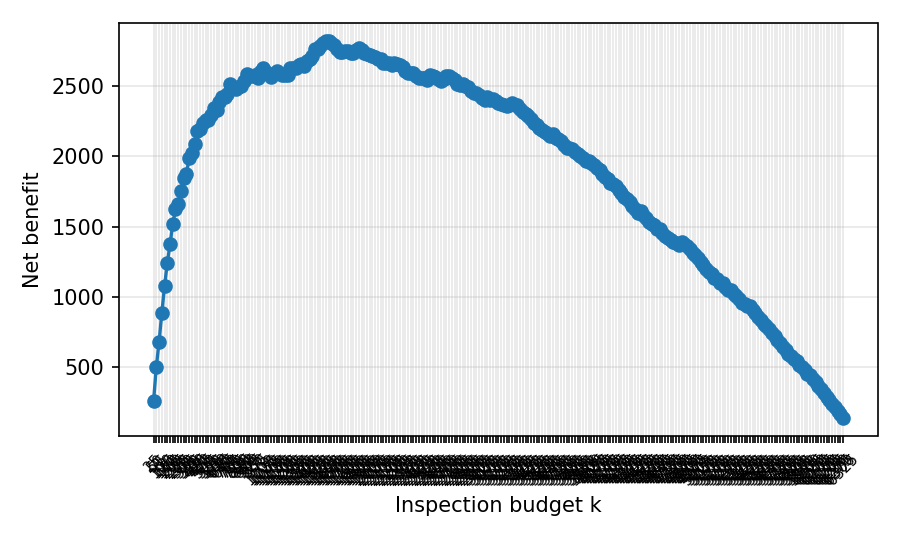

outputs/figures/robustness.png


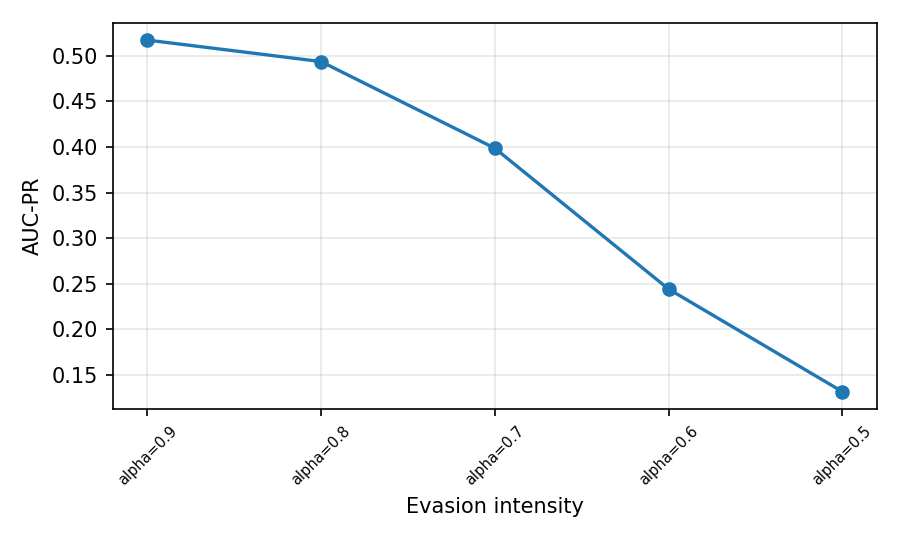

In [ ]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('outputs/figures/*.png')):
    print(f); display(Image(f))

## 6. Inspect the results
Everything is saved to `outputs/results.json`.

In [ ]:
import json, pandas as pd
res = json.load(open('outputs/results.json'))
print("=== Table I: dataset audit ===")
display(pd.Series(res['E0_audit']))
for key, title in [('E1_feature_ablation','Table II: feature ablation'),
                   ('E2_imbalance','Table III: imbalance strategy'),
                   ('E3_models','Table IV: model comparison')]:
    if key in res:
        print(f"\n=== {title} ===")
        display(pd.DataFrame(res[key]))

=== Table I: dataset audit ===


,0
n_customers,42372.000000
n_days,1034.000000
n_thieves,3615.000000
n_benign,38757.000000
theft_rate,0.085316
missing_fraction_overall,0.256399
missing_fraction_thieves,0.314687
missing_fraction_benign,0.250962



=== Table II: feature ablation ===


,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal,n_features
0,STAT,0.725609,0.291006,0.304038,0.265193,0.356215,0.537645,0.66,0.122449,0.474684,...,2.683547,1736.0,0.1675,0.621521,0.244413,1.971466,2020.0,1975,2033.0,23
1,STAT+MISS,0.812325,0.443372,0.435402,0.481982,0.397032,0.617339,0.86,0.159555,0.796602,...,3.472134,2540.0,0.1960,0.727273,0.403324,2.306909,2704.0,1575,2721.0,33
2,STAT+SIG,0.729413,0.300785,0.318782,0.352018,0.291280,0.588160,0.71,0.131725,0.526590,...,2.742397,1796.0,0.1650,0.612245,0.252950,1.942041,1960.0,1525,2027.0,44
3,STAT+MISS+SIG,0.807672,0.437418,0.442577,0.445489,0.439703,0.551315,0.77,0.142857,0.706192,...,3.460364,2528.0,0.1915,0.710575,0.395487,2.253944,2596.0,1775,2653.0,54



=== Table III: imbalance strategy ===


,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,MAP@1000,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal
0,none,0.818536,0.450424,0.434141,0.502439,0.382189,0.239846,0.83,0.153989,0.757091,...,0.367474,3.554523,2624.0,0.2010,0.745826,0.413717,2.365759,2824.0,1975,2849.0
1,class_weight,0.807672,0.437418,0.442577,0.445489,0.439703,0.551315,0.77,0.142857,0.706192,...,0.356173,3.460364,2528.0,0.1915,0.710575,0.395487,2.253944,2596.0,1775,2653.0
2,smote,0.802000,0.409558,0.400356,0.384615,0.417440,0.317290,0.79,0.146568,0.734580,...,0.320356,3.248505,2312.0,0.1960,0.727273,0.370356,2.306909,2704.0,2025,2727.0
3,undersample,0.801569,0.421064,0.413208,0.420345,0.406308,0.845966,0.86,0.159555,0.791938,...,0.334972,3.319124,2384.0,0.1915,0.710575,0.379677,2.253944,2596.0,1575,2709.0



=== Table IV: model comparison ===


,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,MAP@1000,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal
0,logreg,0.761481,0.279201,0.317355,0.286140,0.356215,0.699817,0.53,0.098330,0.370191,...,0.190355,2.883636,1940.0,0.1780,0.660482,0.233216,2.095050,2272.0,1950,2298.0
1,rf,0.783157,0.360527,0.392558,0.393657,0.391466,0.241771,0.71,0.131725,0.555240,...,0.273977,3.154345,2216.0,0.1825,0.677180,0.315409,2.148015,2380.0,1475,2509.0
2,hgb,0.805441,0.431177,0.408320,0.349144,0.491651,0.149007,0.81,0.150278,0.736277,...,0.348701,3.401514,2468.0,0.1915,0.710575,0.388882,2.253944,2596.0,2650,2654.0
3,xgb,0.807672,0.437418,0.442577,0.445489,0.439703,0.551315,0.77,0.142857,0.706192,...,0.356173,3.460364,2528.0,0.1915,0.710575,0.395487,2.253944,2596.0,1775,2653.0
4,lgbm,0.810825,0.450751,0.440349,0.461382,0.421150,0.443418,0.82,0.152134,0.760365,...,0.370627,3.530983,2600.0,0.1965,0.729128,0.412113,2.312794,2716.0,1600,2816.0


## 7. The headline result: leakage inflation

In [ ]:
lk = res.get('E4_leakage')
if lk:
    import pandas as pd
    display(pd.DataFrame([lk['leaky'], lk['correct']]))
    print(f"AUC-ROC inflation from resampling before splitting: {lk['inflation']:+.4f}")
    print(f"AUC-PR  inflation: {lk['leaky']['auc_pr'] - lk['correct']['auc_pr']:+.4f}")

,tag,auc_roc,auc_pr,f1,precision,recall,threshold,P@100,R@100,MAP@100,...,MAP@1000,lift@1000,benefit@1000,P@2000,R@2000,MAP@2000,lift@2000,benefit@2000,k_optimal,benefit_optimal
0,leaky (SMOTE first),0.983755,0.987598,0.948384,0.975414,0.922812,0.5,1.00,0.017229,1.00000,...,1.000000,2.000172,11000.0,1.000,0.344590,1.000000,2.000172,22000.0,7100,61000.0
1,correct (split first),0.802000,0.409558,0.382244,0.569853,0.287570,0.5,0.79,0.146568,0.73458,...,0.320356,3.248505,2312.0,0.196,0.727273,0.370356,2.306909,2704.0,2025,2727.0


AUC-ROC inflation from resampling before splitting: +0.1818
AUC-PR  inflation: +0.5780


## 8. Figures

outputs/figures/cost_curve.png


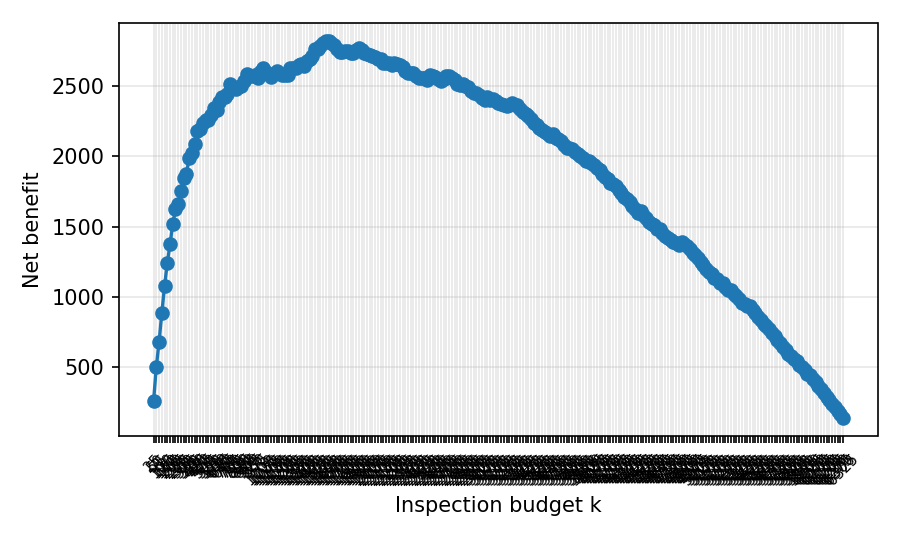

outputs/figures/robustness.png


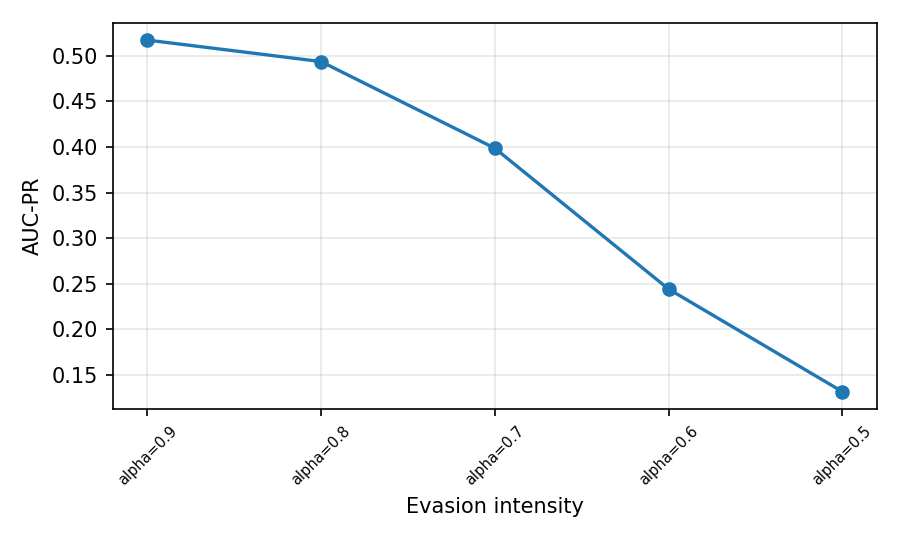

In [ ]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('outputs/figures/*.png')):
    print(f); display(Image(f))

## Exporting Results to CSV

In [ ]:
import pandas as pd
import json
import os

# Ensure the outputs directory exists
os.makedirs('outputs', exist_ok=True)

# Load the results if not already loaded (e.g., if running this cell independently)
if 'res' not in locals():
    res = json.load(open('outputs/results.json'))

# Export E0_audit to CSV
if 'E0_audit' in res:
    pd.Series(res['E0_audit']).to_csv('outputs/E0_audit.csv', header=True)
    print('Saved outputs/E0_audit.csv')

# Export E1_feature_ablation, E2_imbalance, E3_models to CSV
for key, title in [('E1_feature_ablation','feature_ablation'),
                   ('E2_imbalance','imbalance_strategy'),
                   ('E3_models','model_comparison')]:
    if key in res:
        df = pd.DataFrame(res[key])
        filename = f'outputs/{title}.csv'
        df.to_csv(filename, index=False)
        print(f'Saved {filename}')

# Export E4_leakage to CSV
lk = res.get('E4_leakage')
if lk:
    df_leakage = pd.DataFrame([lk['leaky'], lk['correct']])
    df_leakage.to_csv('outputs/leakage_inflation.csv', index=False)
    print('Saved outputs/leakage_inflation.csv')


Saved outputs/E0_audit.csv
Saved outputs/feature_ablation.csv
Saved outputs/imbalance_strategy.csv
Saved outputs/model_comparison.csv
Saved outputs/leakage_inflation.csv


## 9. Experiment yourself

Change the cost model and watch the optimal inspection budget move.
This is the fastest way to understand Contribution C3.

In [ ]:
import sys; sys.path.insert(0,'.')
import importlib, numpy as np
from src import config as C, evaluate as EV

# pretend an inspection is expensive relative to what you recover
C.INSPECTION_COST   = 1.0
C.RECOVERED_REVENUE = 4.0

# reuse the saved curve shape as a demo; on a real run use your model scores
print("Try re-running section 5 after editing these two numbers.")
print("cost =", C.INSPECTION_COST, " revenue =", C.RECOVERED_REVENUE)

Try re-running section 5 after editing these two numbers.
cost = 1.0  revenue = 4.0


## 10. Download everything back to your PC

In [ ]:
!zip -qr results.zip outputs src run_pipeline.py
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

def download_data():
    print("Downloading split archive parts...")
    # 1. Download all split parts from GitHub
    os.system('wget -nc -q https://github.com/henryRDlab/ElectricityTheftDetection/raw/master/data.z01')
    os.system('wget -nc -q https://github.com/henryRDlab/ElectricityTheftDetection/raw/master/data.z02')
    os.system('wget -nc -q https://github.com/henryRDlab/ElectricityTheftDetection/raw/master/data.zip')

    print("Combining split parts into a single zip file...")
    # 2. Combine the parts into a unified zip archive
    os.system('zip -s 0 data.zip --out combined_data.zip')

    print("Extracting files...")
    # 3. Extract the combined zip file
    os.system('unzip -q combined_data.zip')
    print("Done! Data downloaded and extracted successfully.")

# Call the function to run it
download_data()


Combining split parts into a single zip file...
Extracting files...
Done! Data downloaded and extracted successfully.
